# Information of Project

**Project 14 — Corporate Credit Ratings**
FI505E Coding and Data Science for Finance · Bootcamp · Prof. Dr. Sadoghi · Autumn 2026
Prepared by: ASRIR KARIM

**Description and objective (project brief).** Predict corporate credit ratings (AAA to D) from
financial indicators to assess a firm's ability to repay its debt. The objective is to build a
**robust classifier for unbalanced rating data**.

**Suggested method (project brief).** Random Forest or Gradient Boosting for multi-class
classification; handle imbalance with techniques such as **oversampling**.

**Learning objective (project brief).** Develop multi-class models for credit ratings, handle
unbalanced data, and interpret financial indicators.

**Dataset.** Kaggle *Corporate Credit Rating* (agewerc): 2,029 ratings issued 2010–2016 by S&P,
Moody's, Fitch, Egan-Jones and DBRS on US-listed firms, with 25 financial indicators
(liquidity, profitability, leverage, efficiency, cash flow).
https://www.kaggle.com/datasets/agewerc/corporate-credit-rating

**Models.** Following the course template: Decision Tree, Linear SVM and Non-linear (RBF) SVM;
following the Project 14 brief: Random Forest and Gradient Boosting. Every model is trained with
SMOTE oversampling inside the training pipeline.

##Group_2 (Name – Student No.) 1.OUELDLIMAME Anas 2.BENALILOU Zaid 3.Jose Ashvin 4.Mahmoud BERRADA 5.Ameliya KASHNITSKAYA

In [2]:
# Setup (Google Colab: imbalanced-learn may need installing)
!pip install -q imbalanced-learn

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, auc, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedGroupKFold,
                                     cross_validate, train_test_split)
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200, "display.max_columns", 40)
SEED = 42

# Import dataset

> Import `corporate_rating.csv` (downloaded from Kaggle). In Colab, the cell asks you to
> upload the file if it is not already in the working folder.

In [3]:
import os
import pandas as pd

DATA_PATH = "/content/corporate_rating (1).csv"
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        DATA_PATH = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError("Place corporate_rating.csv (Kaggle) next to this notebook.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Shape: (2029, 31)
Missing values: 0


,Rating,Name,Symbol,Rating Agency Name,Date,Sector,currentRatio,quickRatio,cashRatio,daysOfSalesOutstanding,netProfitMargin,pretaxProfitMargin,grossProfitMargin,operatingProfitMargin,returnOnAssets,returnOnCapitalEmployed,returnOnEquity,assetTurnover,fixedAssetTurnover,debtEquityRatio,debtRatio,effectiveTaxRate,freeCashFlowOperatingCashFlowRatio,freeCashFlowPerShare,cashPerShare,companyEquityMultiplier,ebitPerRevenue,enterpriseValueMultiple,operatingCashFlowPerShare,operatingCashFlowSalesRatio,payablesTurnover
0,A,Whirlpool Corporation,WHR,Egan-Jones Ratings Company,11/27/2015,Consumer Durables,0.945894,0.426395,0.099690,44.203245,0.037480,0.049351,0.176631,0.061510,0.041189,0.091514,0.165085,1.098948,5.535506,3.008012,0.750500,0.202716,0.437551,6.810673,9.809403,4.008012,0.049351,7.057088,15.565438,0.058638,3.906655
1,BBB,Whirlpool Corporation,WHR,Egan-Jones Ratings Company,2/13/2014,Consumer Durables,1.033559,0.498234,0.203120,38.991156,0.044062,0.048857,0.175715,0.066546,0.053204,0.104800,0.167953,1.207476,6.171983,2.156783,0.683222,0.074155,0.541997,8.625473,17.402270,3.156783,0.048857,6.460618,15.914250,0.067239,4.002846
2,BBB,Whirlpool Corporation,WHR,Fitch Ratings,3/6/2015,Consumer Durables,0.963703,0.451505,0.122099,50.841385,0.032709,0.044334,0.170843,0.059783,0.032497,0.075955,0.133060,0.993501,4.991711,3.094575,0.755774,0.214529,0.513185,9.693487,13.103448,4.094575,0.044334,10.491970,18.888889,0.074426,3.483510
3,BBB,Whirlpool Corporation,WHR,Fitch Ratings,6/15/2012,Consumer Durables,1.019851,0.510402,0.176116,41.161738,0.020894,-0.012858,0.138059,0.042430,0.025690,-0.027015,0.093279,1.229563,6.017408,2.630950,0.724590,1.816667,-0.147170,-1.015625,14.440104,3.630950,-0.012858,4.080741,6.901042,0.028394,4.581150
4,BBB,Whirlpool Corporation,WHR,Standard & Poor's Ratings Services,10/24/2016,Consumer Durables,0.957844,0.495432,0.141608,47.761126,0.042861,0.053770,0.177720,0.065354,0.046363,0.096945,0.186047,1.081710,5.437795,3.012780,0.750796,0.166966,0.451372,7.135348,14.257556,4.012780,0.053770,8.293505,15.808147,0.058065,3.857790


In [4]:
INFO_COLS = ["Rating", "Name", "Symbol", "Rating Agency Name", "Date", "Sector"]
FEATURES = [c for c in df.columns if c not in INFO_COLS]   # the 25 financial indicators
print(len(FEATURES), "financial indicators:", FEATURES)
print("\nCompanies:", df["Symbol"].nunique(), "| ratings per company (median):",
      df.groupby("Symbol").size().median())
print("\nRating agencies:\n", df["Rating Agency Name"].value_counts())
print("\nOriginal rating distribution:\n", df["Rating"].value_counts().reindex(
    ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "CC", "C", "D"]))

25 financial indicators: ['currentRatio', 'quickRatio', 'cashRatio', 'daysOfSalesOutstanding', 'netProfitMargin', 'pretaxProfitMargin', 'grossProfitMargin', 'operatingProfitMargin', 'returnOnAssets', 'returnOnCapitalEmployed', 'returnOnEquity', 'assetTurnover', 'fixedAssetTurnover', 'debtEquityRatio', 'debtRatio', 'effectiveTaxRate', 'freeCashFlowOperatingCashFlowRatio', 'freeCashFlowPerShare', 'cashPerShare', 'companyEquityMultiplier', 'ebitPerRevenue', 'enterpriseValueMultiple', 'operatingCashFlowPerShare', 'operatingCashFlowSalesRatio', 'payablesTurnover']

Companies: 593 | ratings per company (median): 3.0

Rating agencies:
 Rating Agency Name
Standard & Poor's Ratings Services    744
Egan-Jones Ratings Company            603
Moody's Investors Service             579
Fitch Ratings                         100
DBRS                                    3
Name: count, dtype: int64

Original rating distribution:
 Rating
AAA      7
AA      89
A      398
BBB    671
BB     490
B      302
CCC

**Target classes.** Four original ratings are almost empty: AAA (7), CC (5), C (2) and D (1).
A class with 1–2 observations cannot be split 80/20, learned or evaluated. We therefore group
ratings into **6 ordered classes** that keep the AAA → D scale and the investment-grade line:

| Class | Original ratings | Grade |
|---|---|---|
| AAA/AA | AAA, AA | Investment grade |
| A | A | Investment grade |
| BBB | BBB | Investment grade |
| BB | BB | High yield |
| B | B | High yield |
| CCC–D | CCC, CC, C, D | High yield (distressed) |

In [5]:
GROUPING = {"AAA": "AAA/AA", "AA": "AAA/AA", "A": "A", "BBB": "BBB", "BB": "BB", "B": "B",
            "CCC": "CCC-D", "CC": "CCC-D", "C": "CCC-D", "D": "CCC-D"}
CLASSES = ["AAA/AA", "A", "BBB", "BB", "B", "CCC-D"]          # best → worst
df["RatingClass"] = pd.Categorical(df["Rating"].map(GROUPING), categories=CLASSES, ordered=True)
df["y"] = df["RatingClass"].cat.codes                          # 0 = best
IG_CUT = CLASSES.index("BBB")       # classes 0..2 = investment grade, 3..5 = high yield
print(df["RatingClass"].value_counts().reindex(CLASSES).to_frame("firms").assign(
    share=lambda t: (t.firms / t.firms.sum()).round(3)))

             firms  share
RatingClass              
AAA/AA          96  0.047
A              398  0.196
BBB            671  0.331
BB             490  0.241
B              302  0.149
CCC-D           72  0.035


# Understanding data

Provide statistical description of data

In [6]:
desc = df[FEATURES].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc["skew"] = df[FEATURES].skew()
desc.round(3)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew
currentRatio,2029.0,3.530,44.052,-0.932,0.312,1.072,1.493,2.167,10.310,1725.505,34.339
quickRatio,2029.0,2.654,32.945,-1.893,0.053,0.603,0.986,1.454,10.697,1139.542,30.926
cashRatio,2029.0,0.667,3.584,-0.193,0.001,0.131,0.297,0.625,4.322,125.917,27.099
daysOfSalesOutstanding,2029.0,333.796,4447.840,-811.846,0.000,22.905,42.374,59.324,1683.498,115961.637,20.400
netProfitMargin,2029.0,0.278,6.064,-101.846,-1.290,0.021,0.065,0.115,0.810,198.518,17.620
pretaxProfitMargin,2029.0,0.431,8.985,-124.344,-1.653,0.026,0.085,0.145,1.159,309.695,22.096
grossProfitMargin,2029.0,0.498,0.525,-14.801,0.005,0.233,0.415,0.850,1.000,2.703,-14.203
operatingProfitMargin,2029.0,0.587,11.225,-124.344,-1.485,0.045,0.108,0.176,0.796,410.182,26.494
returnOnAssets,2029.0,-37.518,1166.172,-40213.178,-0.360,0.019,0.046,0.077,0.225,0.488,-32.113
returnOnCapitalEmployed,2029.0,-73.974,2350.276,-87162.162,-0.473,0.028,0.074,0.135,0.440,2.440,-33.319


In [7]:
# Median of each indicator per rating class (medians are robust to the extreme outliers)
med = df.groupby("RatingClass", observed=False)[FEATURES].median().T
med.round(3)

RatingClass,AAA/AA,A,BBB,BB,B,CCC-D
currentRatio,1.512,1.339,1.434,1.674,1.622,1.584
quickRatio,1.056,0.849,0.930,1.140,1.064,1.024
cashRatio,0.331,0.246,0.278,0.374,0.289,0.364
daysOfSalesOutstanding,41.136,39.965,42.373,43.879,43.980,40.183
netProfitMargin,0.116,0.094,0.073,0.046,0.018,-0.041
pretaxProfitMargin,0.146,0.123,0.093,0.058,0.024,-0.044
grossProfitMargin,0.611,0.489,0.385,0.348,0.413,0.828
operatingProfitMargin,0.157,0.141,0.119,0.079,0.059,0.009
returnOnAssets,0.093,0.067,0.049,0.033,0.016,-0.019
returnOnCapitalEmployed,0.161,0.132,0.082,0.053,0.029,-0.014


Provide interpertation of statistical description of data and highlight suprising and intersting points and insert to cell

1. **Clean but noisy data.** 2,029 ratings on 593 companies, no missing values, but the raw
   ratios contain obvious **data errors**: assetTurnover reaches 2.55 million, returnOnAssets falls
   to −40,213, daysOfSalesOutstanding reaches 115,962 days (317 years) and currentRatio has
   negative values, which is impossible. Means and standard deviations are therefore meaningless
   (mean ROA = −37.5 while the median is 0.046), so we read **medians** and winsorise at 1%/99%.
2. **Typical firm.** The median firm has a current ratio of 1.49, a debt ratio of 0.64, a net
   margin of 6.5% and an ROA of 4.6%: plausible values for large US listed companies.
3. **Profitability falls steadily with the rating.** Median net margin goes from 11.6% (AAA/AA) to
   9.4% (A), 7.3% (BBB), 4.6% (BB), 1.8% (B) and −4.1% (CCC–D); ROA from 9.3% to −1.9%;
   operating cash flow per share from 7.8 to 1.3. This is exactly what rating agencies look for.
4. **Leverage rises with risk.** Median debt ratio: 0.58 (AAA/AA) → 0.64 (BB) → 0.74 (B) → 0.83
   (CCC–D); debt/equity: 1.27 → 2.21.
5. **Surprising: liquidity does not improve the rating.** BB firms have a higher median current
   ratio (1.67) than A firms (1.34). Strong firms run lean working capital because they can borrow
   cheaply at any time; weaker firms must hold cash as a buffer.
6. **Surprising: CCC–D firms have the highest gross margin (0.83)** but negative net margins. This
   reflects their sectors (energy, technology, health care with little cost of goods sold) and
   heavy costs below gross profit (interest, R&D, write-downs). Gross margin alone says little
   about credit risk.
7. **Distressed firms pay suppliers slowly:** median payables turnover 1.9 for CCC–D vs 5–6.5 for
   the other classes, i.e. they stretch payables to preserve cash.
8. **Strong class imbalance:** BBB = 33% of ratings, CCC–D = 3.5%, AAA/AA = 4.7%. A model that
   always predicts BBB is 33% accurate, so accuracy alone is misleading.

Give histgram of data

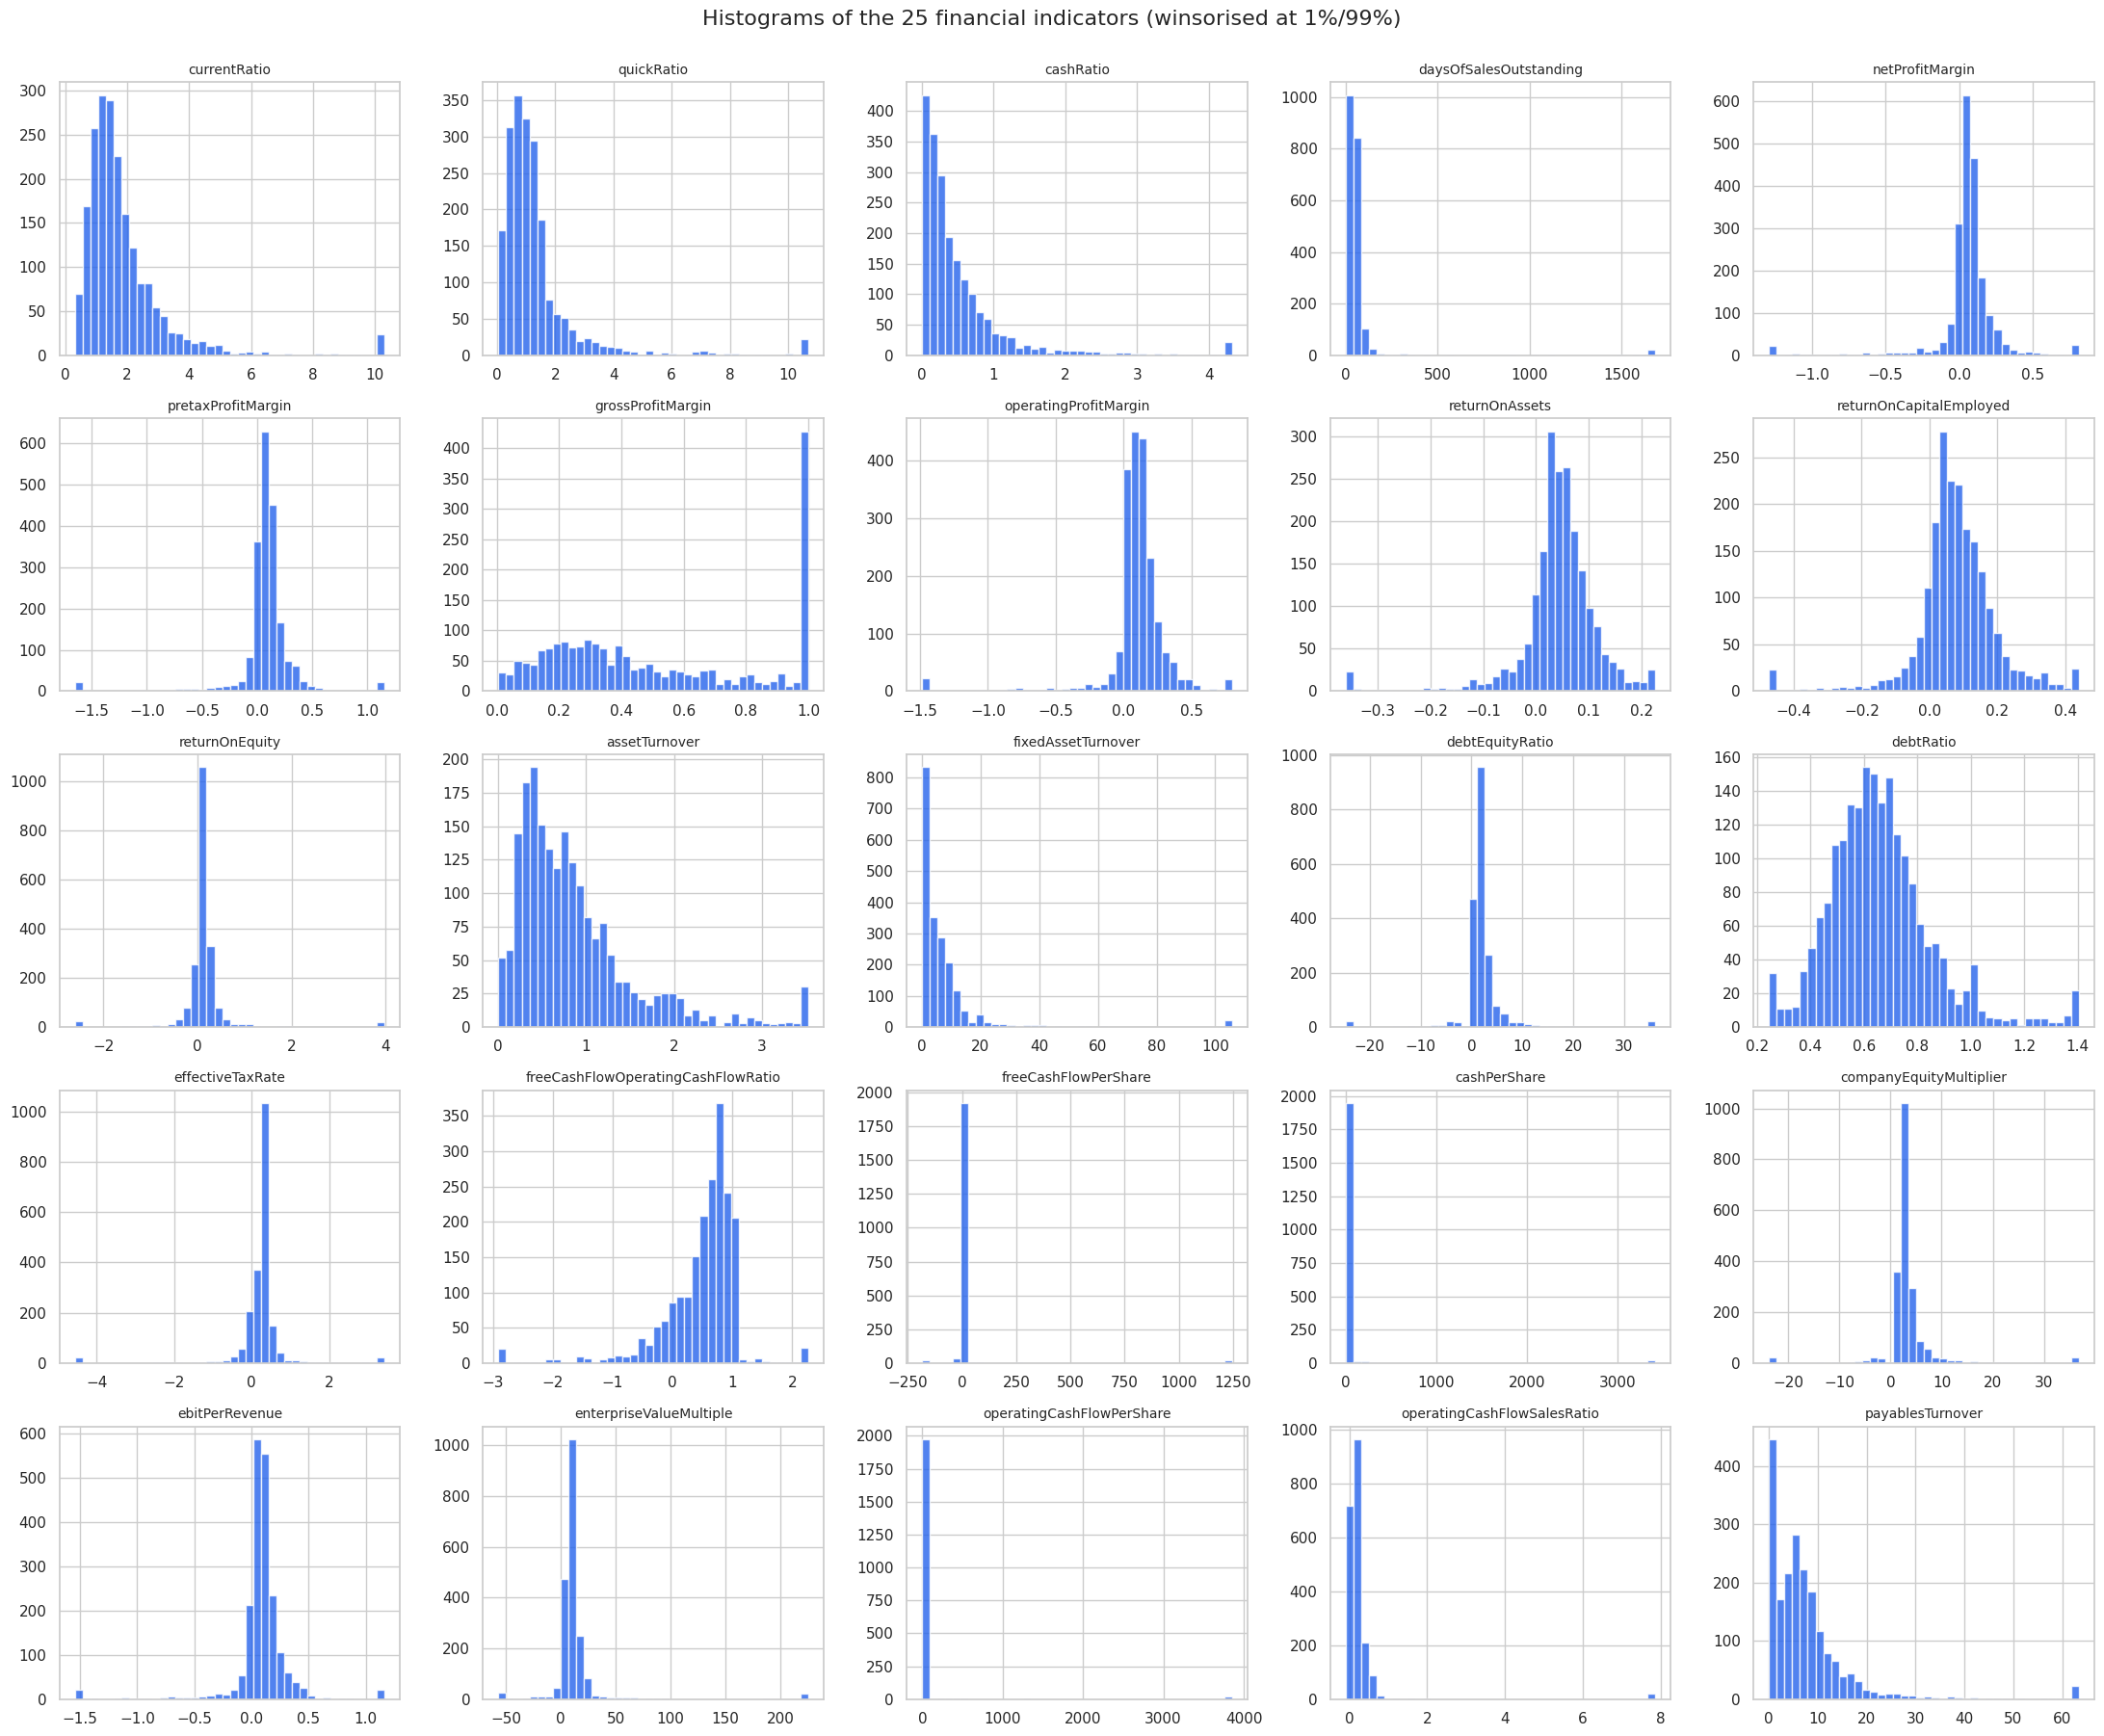

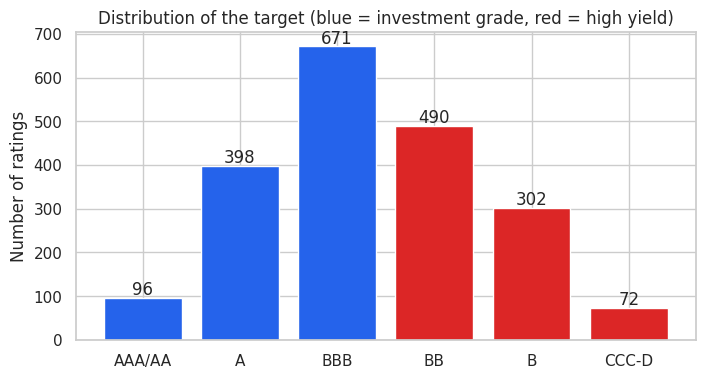

In [8]:
# Winsorise at the 1st/99th percentiles for display only: raw maxima are data errors
# (e.g. assetTurnover = 2.5 million) and would squash every histogram into one bar.
q_lo, q_hi = df[FEATURES].quantile(0.01), df[FEATURES].quantile(0.99)
dfw = df[FEATURES].clip(q_lo, q_hi, axis=1)

fig, axes = plt.subplots(5, 5, figsize=(22, 18))
for ax, f in zip(axes.ravel(), FEATURES):
    ax.hist(dfw[f], bins=40, color="#2563eb", alpha=0.8)
    ax.set_title(f, fontsize=10)
fig.suptitle("Histograms of the 25 financial indicators (winsorised at 1%/99%)", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
counts = df["RatingClass"].value_counts().reindex(CLASSES)
plt.bar(CLASSES, counts, color=["#2563eb"] * 3 + ["#dc2626"] * 3)
for i, v in enumerate(counts):
    plt.text(i, v + 8, v, ha="center")
plt.title("Distribution of the target (blue = investment grade, red = high yield)")
plt.ylabel("Number of ratings")
plt.show()

Provide interpertation of histogram of data and highlight suprising and intersting points and insert to cell

1. **Heavy tails everywhere.** Even after winsorising at 1%/99%, most ratios pile up near zero with
   a long right tail (currentRatio, cashRatio, turnover ratios, per-share figures); the small bars
   at the edges are the capped outliers. Skewness above 20 for most raw ratios confirms it.
2. **Per-share figures are not comparable across firms.** freeCashFlowPerShare, cashPerShare and
   operatingCashFlowPerShare depend on the number of shares, not on credit quality, and produce
   one tall bar near zero. Ratios scaled by sales or assets are more informative.
3. **Margins and returns are centred on a positive value with a left tail of loss-makers**
   (net margin peak around 5–10%, ROA around 5%). That left tail is where the B and CCC–D firms sit.
4. **Surprising spike: grossProfitMargin = 1.0 for 411 ratings (20%).** These firms report
   no cost of goods sold (utilities, services, some financials and tech), so their gross margin
   is 100% by construction. It is an accounting artefact, not a sign of strength.
5. **debtRatio is the only close-to-normal ratio** (centred at 0.64), with a tail above 1.0:
   firms with **negative equity** (liabilities > assets). debtEquityRatio and
   companyEquityMultiplier also show negative values for the same reason.
6. **Consequences for modelling:** tree models (split on thresholds) are insensitive to skewness;
   SVMs are distance-based and need winsorised and standardised inputs, which our pipeline does.

Provide correlation matrix of data

In [9]:
corr = dfw.corr()          # Pearson on winsorised data (raw outliers would dominate Pearson)
corr.round(2)

,currentRatio,quickRatio,cashRatio,daysOfSalesOutstanding,netProfitMargin,pretaxProfitMargin,grossProfitMargin,operatingProfitMargin,returnOnAssets,returnOnCapitalEmployed,returnOnEquity,assetTurnover,fixedAssetTurnover,debtEquityRatio,debtRatio,effectiveTaxRate,freeCashFlowOperatingCashFlowRatio,freeCashFlowPerShare,cashPerShare,companyEquityMultiplier,ebitPerRevenue,enterpriseValueMultiple,operatingCashFlowPerShare,operatingCashFlowSalesRatio,payablesTurnover
currentRatio,1.00,0.76,0.74,0.12,-0.01,-0.01,-0.11,0.00,0.01,-0.05,-0.07,-0.07,0.07,-0.04,-0.21,-0.05,0.12,0.05,0.14,-0.05,-0.01,0.05,-0.01,0.05,0.12
quickRatio,0.76,1.00,0.63,0.22,0.02,0.02,0.02,0.04,0.01,-0.05,-0.05,-0.15,0.05,-0.01,-0.12,-0.04,0.11,0.03,0.13,-0.01,0.02,0.05,-0.01,0.10,0.06
cashRatio,0.74,0.63,1.00,0.11,-0.04,-0.03,-0.05,-0.01,-0.01,-0.04,-0.03,-0.15,-0.00,-0.06,-0.15,-0.05,0.06,0.01,0.02,-0.07,-0.03,0.02,-0.03,0.08,0.10
daysOfSalesOutstanding,0.12,0.22,0.11,1.00,0.17,0.22,0.06,0.14,-0.03,-0.05,-0.02,-0.17,-0.04,-0.01,-0.03,0.01,0.02,0.09,0.15,-0.01,0.24,0.03,0.02,0.81,-0.08
netProfitMargin,-0.01,0.02,-0.04,0.17,1.00,0.93,0.07,0.90,0.73,0.59,0.15,-0.05,-0.00,0.00,-0.12,0.02,0.07,0.05,-0.00,0.00,0.93,0.04,0.04,0.17,0.01
pretaxProfitMargin,-0.01,0.02,-0.03,0.22,0.93,1.00,0.07,0.94,0.67,0.61,0.14,-0.04,-0.01,0.01,-0.10,0.04,0.06,0.05,-0.00,0.01,1.00,0.03,0.04,0.21,0.02
grossProfitMargin,-0.11,0.02,-0.05,0.06,0.07,0.07,1.00,0.10,-0.04,-0.07,-0.01,-0.44,-0.07,0.01,0.05,0.02,0.03,0.05,0.03,0.01,0.07,0.00,0.08,0.18,-0.38
operatingProfitMargin,0.00,0.04,-0.01,0.14,0.90,0.94,0.10,1.00,0.68,0.60,0.14,-0.08,-0.02,0.01,-0.09,0.05,0.07,0.04,-0.00,0.01,0.94,0.04,0.04,0.13,0.02
returnOnAssets,0.01,0.01,-0.01,-0.03,0.73,0.67,-0.04,0.68,1.00,0.88,0.20,0.14,0.01,0.00,-0.15,0.04,0.18,0.04,0.00,0.00,0.67,0.01,0.07,-0.03,0.10
returnOnCapitalEmployed,-0.05,-0.05,-0.04,-0.05,0.59,0.61,-0.07,0.60,0.88,1.00,0.19,0.27,0.08,0.02,-0.07,0.08,0.18,0.03,-0.02,0.02,0.62,-0.01,0.05,-0.06,0.12


Provide heatmap of correlation matrix of data

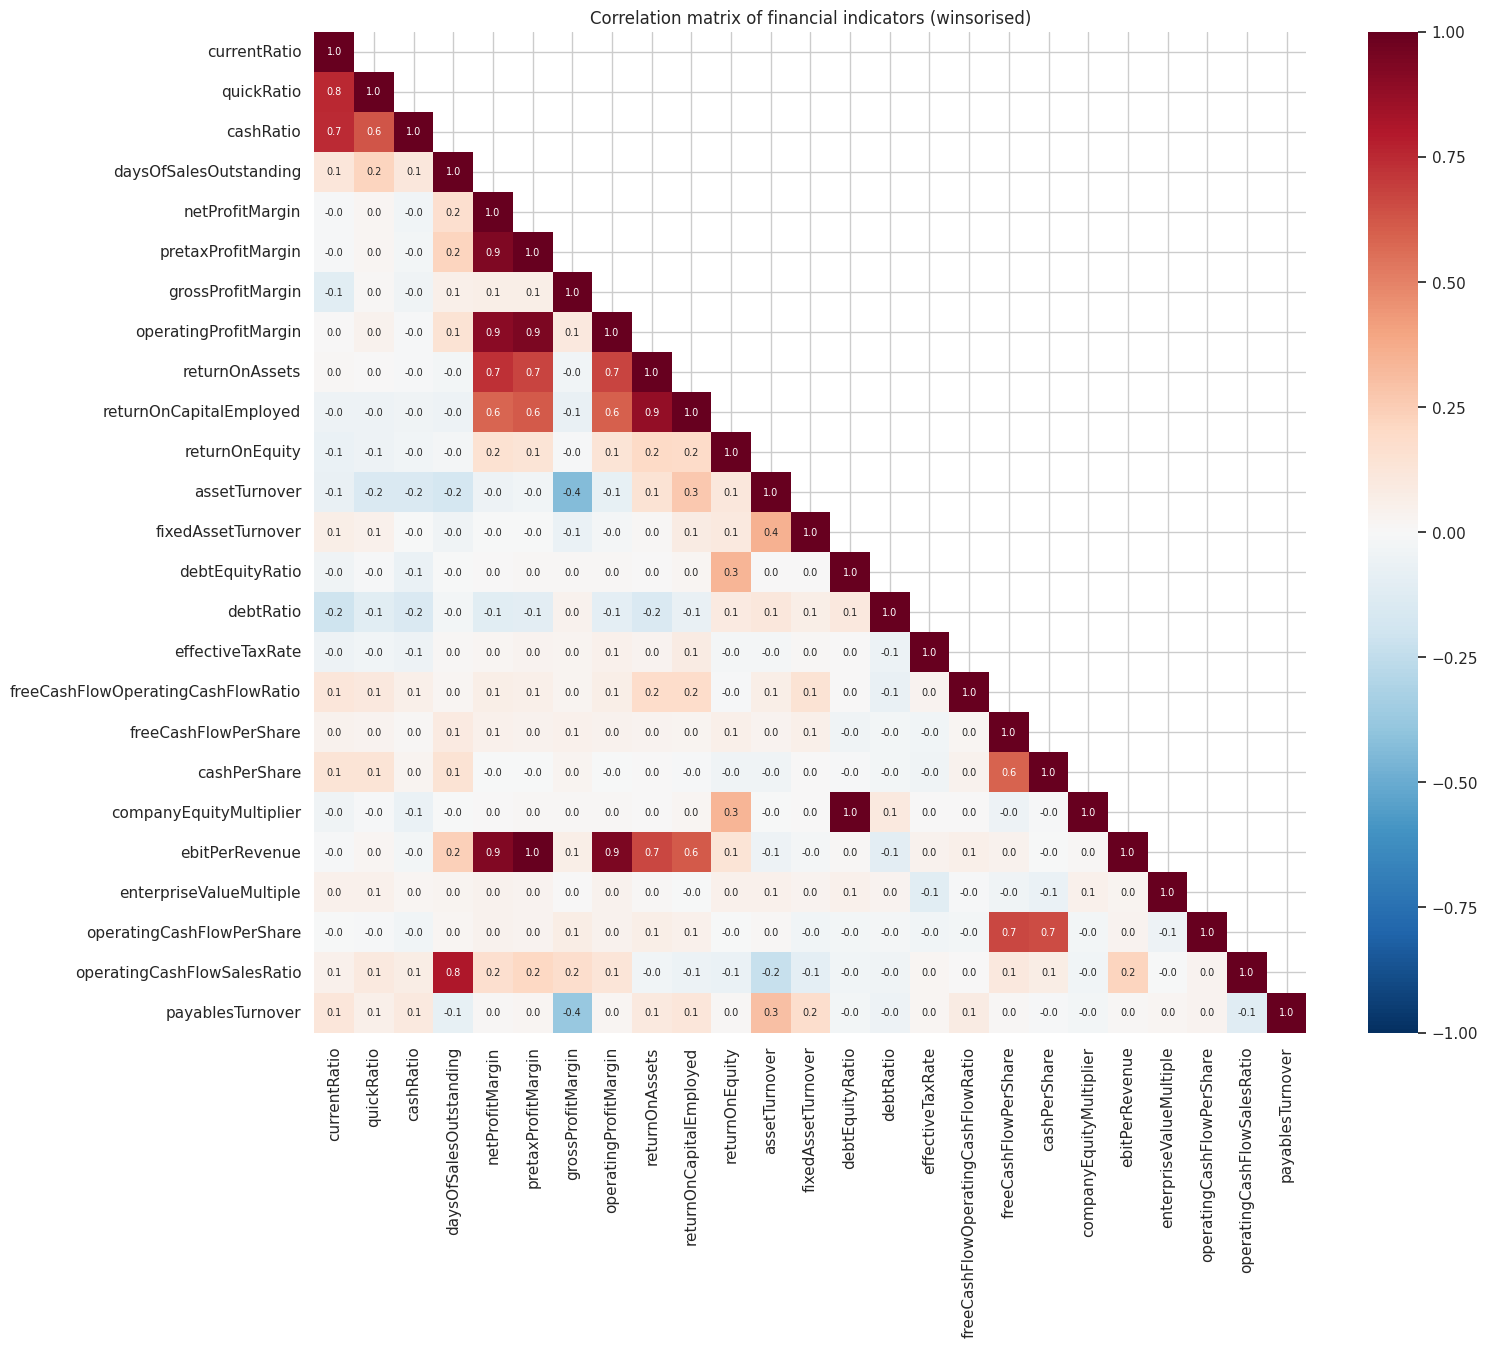

Most correlated pairs:
                level_0                     level_1     r  abs_r
       debtEquityRatio     companyEquityMultiplier 0.999  0.999
    pretaxProfitMargin              ebitPerRevenue 0.995  0.995
    pretaxProfitMargin       operatingProfitMargin 0.943  0.943
 operatingProfitMargin              ebitPerRevenue 0.941  0.941
       netProfitMargin          pretaxProfitMargin 0.931  0.931
       netProfitMargin              ebitPerRevenue 0.925  0.925
       netProfitMargin       operatingProfitMargin 0.905  0.905
        returnOnAssets     returnOnCapitalEmployed 0.882  0.882
daysOfSalesOutstanding operatingCashFlowSalesRatio 0.810  0.810
          currentRatio                  quickRatio 0.757  0.757

Spearman correlation with rating rank (positive = associated with WORSE rating):
 returnOnCapitalEmployed              -0.443
returnOnAssets                       -0.439
pretaxProfitMargin                   -0.408
ebitPerRevenue                       -0.398
operatingCash

In [10]:
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7},
            mask=np.triu(np.ones_like(corr, dtype=bool), 1))
plt.title("Correlation matrix of financial indicators (winsorised)")
plt.show()

pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack()
         .rename("r").reset_index().assign(abs_r=lambda t: t.r.abs())
         .sort_values("abs_r", ascending=False))
print("Most correlated pairs:\n", pairs.head(10).round(3).to_string(index=False))

# Correlation of each indicator with the rating (Spearman, rank-based: 0 = best rating)
rho = df[FEATURES].corrwith(df["y"], method="spearman").sort_values()
print("\nSpearman correlation with rating rank (positive = associated with WORSE rating):\n",
      rho.round(3).to_string())

Provide interpertation of histoheatmap of correlation mgram of data and highlight suprising and

1. **Two pairs are the same variable.** companyEquityMultiplier vs debtEquityRatio (r = 0.999):
   equity multiplier = 1 + debt/equity by definition. ebitPerRevenue vs pretaxProfitMargin
   (r = 0.995): they differ only by interest expense. The dataset really holds ~23 independent
   pieces of information, not 25.
2. **Profitability is one block.** Net, pre-tax, operating margins and EBIT/revenue correlate at
   0.90–0.94; ROA and ROCE at 0.88. Profitability is the strongest family of signals but is
   measured several times.
3. **Liquidity is a second block** (current vs quick ratio r = 0.76, vs cash ratio 0.74), almost
   uncorrelated with profitability (|r| < 0.05): a firm can be liquid and unprofitable.
4. **Surprising: daysOfSalesOutstanding vs operatingCashFlowSalesRatio r = 0.81** — both are
   driven by the same extreme observations (firms with tiny revenue), not by an economic link.
5. **Link with the rating (Spearman, rank-based).** The strongest associations are returns and
   margins: ROCE ρ = −0.44, ROA −0.44, pre-tax margin −0.41, operating cash flow per share −0.39
   (negative = higher value → better rating). Leverage goes the other way (debtRatio ρ = +0.22).
   Liquidity ratios have a weak *positive* ρ (+0.12), confirming the surprise noted above.
6. **No single ratio is strongly correlated with the rating** (max |ρ| = 0.44): ratings combine
   many dimensions, which is why a multivariate model is needed and why accuracy will be limited.
7. **Implication:** strong multicollinearity does not hurt tree ensembles' predictions, but it
   splits importance between twin variables (see the importance chart below) and makes
   single-variable interpretation fragile.

# Split dataset

use these varibles as Independent variables (X): the 25 financial indicators
(`currentRatio`, `quickRatio`, `cashRatio`, `daysOfSalesOutstanding`, `netProfitMargin`,
`pretaxProfitMargin`, `grossProfitMargin`, `operatingProfitMargin`, `returnOnAssets`,
`returnOnCapitalEmployed`, `returnOnEquity`, `assetTurnover`, `fixedAssetTurnover`,
`debtEquityRatio`, `debtRatio`, `effectiveTaxRate`, `freeCashFlowOperatingCashFlowRatio`,
`freeCashFlowPerShare`, `cashPerShare`, `companyEquityMultiplier`, `ebitPerRevenue`,
`enterpriseValueMultiple`, `operatingCashFlowPerShare`, `operatingCashFlowSalesRatio`,
`payablesTurnover`)

use these varibles as Dependent variables (y): `RatingClass` (6 ordered classes, AAA/AA … CCC–D)

spliet data to 80-20 — **stratified by rating and grouped by company**. The same company is
rated several times (by different agencies and on different dates) with almost identical ratios.
A plain random split would put the same firm in train and test, and the model would simply
recognise the company (data leakage). We keep every company entirely in train or in test.

In [11]:
X = df[FEATURES].values.astype(float)
y = df["y"].values
groups = df["Symbol"].values

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X, y, groups))       # one fold out of five = 20% test
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]

print(f"Train: {len(y_train)} ratings ({len(y_train) / len(y):.0%}), "
      f"{len(set(g_train))} companies")
print(f"Test : {len(y_test)} ratings ({len(y_test) / len(y):.0%}), "
      f"{len(set(groups[test_idx]))} companies")
print("Companies in both sets:", len(set(g_train) & set(groups[test_idx])))
pd.DataFrame({"train": pd.Series(y_train).value_counts(normalize=True).sort_index().values,
              "test": pd.Series(y_test).value_counts(normalize=True).sort_index().values},
             index=CLASSES).round(3)

Train: 1630 ratings (80%), 474 companies
Test : 399 ratings (20%), 119 companies
Companies in both sets: 0


,train,test
AAA/AA,0.043,0.065
A,0.193,0.208
BBB,0.348,0.261
BB,0.236,0.266
B,0.152,0.138
CCC-D,0.029,0.063


### Pre-processing and handling of imbalance (fitted on the training set only)

1. **Winsorisation** at the 1st/99th percentiles of the *training* data — caps the data errors.
2. **Standardisation** (SVMs only) — SVMs are distance-based and need comparable scales.
3. **SMOTE oversampling** — creates synthetic examples of minority classes by interpolating
   between neighbouring firms of the same class, until every class has as many training
   examples as the largest one. It sits **inside** the pipeline, so it is applied only to the
   training folds and the test set keeps its real, unbalanced distribution.

Hyper-parameters are tuned with 5-fold cross-validation **on the training set only**
(grouped by company), scored by **macro F1** — the average F1 over the six classes, which gives
rare classes the same weight as BBB.

In [12]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each feature to the [lower, upper] quantiles learned on the training data."""

    def __init__(self, lower=0.01, upper=0.99, n_cols=None):
        self.lower, self.upper, self.n_cols = lower, upper, n_cols   # n_cols: clip first n only

    def fit(self, X, y=None):
        n = X.shape[1] if self.n_cols is None else self.n_cols
        self.lo_ = np.quantile(X[:, :n], self.lower, axis=0)
        self.hi_ = np.quantile(X[:, :n], self.upper, axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        n = len(self.lo_)
        X[:, :n] = np.clip(X[:, :n], self.lo_, self.hi_)
        return X


inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = "f1_macro"
RESULTS = {}      # test-set results of every model, filled below


def tune(pipe, grid):
    gs = GridSearchCV(pipe, grid, cv=inner_cv, scoring=SCORING, n_jobs=-1)
    gs.fit(X_train, y_train, groups=g_train)
    print("Best parameters:", gs.best_params_, f"| CV macro F1 = {gs.best_score_:.3f}")
    return gs.best_estimator_


def evaluate(name, model):
    """Print 'Model Performance' + confusion matrix, store results for the summary."""
    proba = model.predict_proba(X_test)
    pred = proba.argmax(1)
    res = {
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "Within ±1 class": np.mean(np.abs(pred - y_test) <= 1),
        "IG vs HY accuracy": np.mean((pred <= IG_CUT) == (y_test <= IG_CUT)),
        "Macro AUC (OvR)": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
    }
    RESULTS[name] = {**res, "proba": proba, "pred": pred}
    print(f"{name} Model Performance:")
    for k, v in res.items():
        print(f"  {k:<20}{v:.3f}")
    print("\nClassification report:\n",
          classification_report(y_test, pred, target_names=CLASSES, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=range(len(CLASSES)))
    print("Confusion Matrix:")
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                xticklabels=CLASSES, yticklabels=CLASSES)
    ax[0].set(title=f"{name} — confusion matrix (counts)", xlabel="Predicted", ylabel="Actual")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".0%", cmap="Blues", cbar=False,
                ax=ax[1], xticklabels=CLASSES, yticklabels=CLASSES)
    ax[1].set(title="Row-normalised (recall per class)", xlabel="Predicted", ylabel="Actual")
    plt.tight_layout()
    plt.show()


def plot_roc(name):
    proba = RESULTS[name]["proba"]
    Yb = label_binarize(y_test, classes=range(len(CLASSES)))
    plt.figure(figsize=(7, 6))
    for k, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Yb[:, k], proba[:, k])
        plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.2f})")
    fpr, tpr, _ = roc_curve(Yb.ravel(), proba.ravel())
    plt.plot(fpr, tpr, "k--", lw=2.5, label=f"Micro-average (AUC = {auc(fpr, tpr):.2f})")
    plt.plot([0, 1], [0, 1], ":", color="grey")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(f"ROC curves (one-vs-rest) — {name}")
    plt.legend(loc="lower right", fontsize=9)
    plt.show()

# Tree Models

provide Tree decision model and plot decisition tree

Best parameters: {'model__max_depth': 4, 'model__min_samples_leaf': 20} | CV macro F1 = 0.259


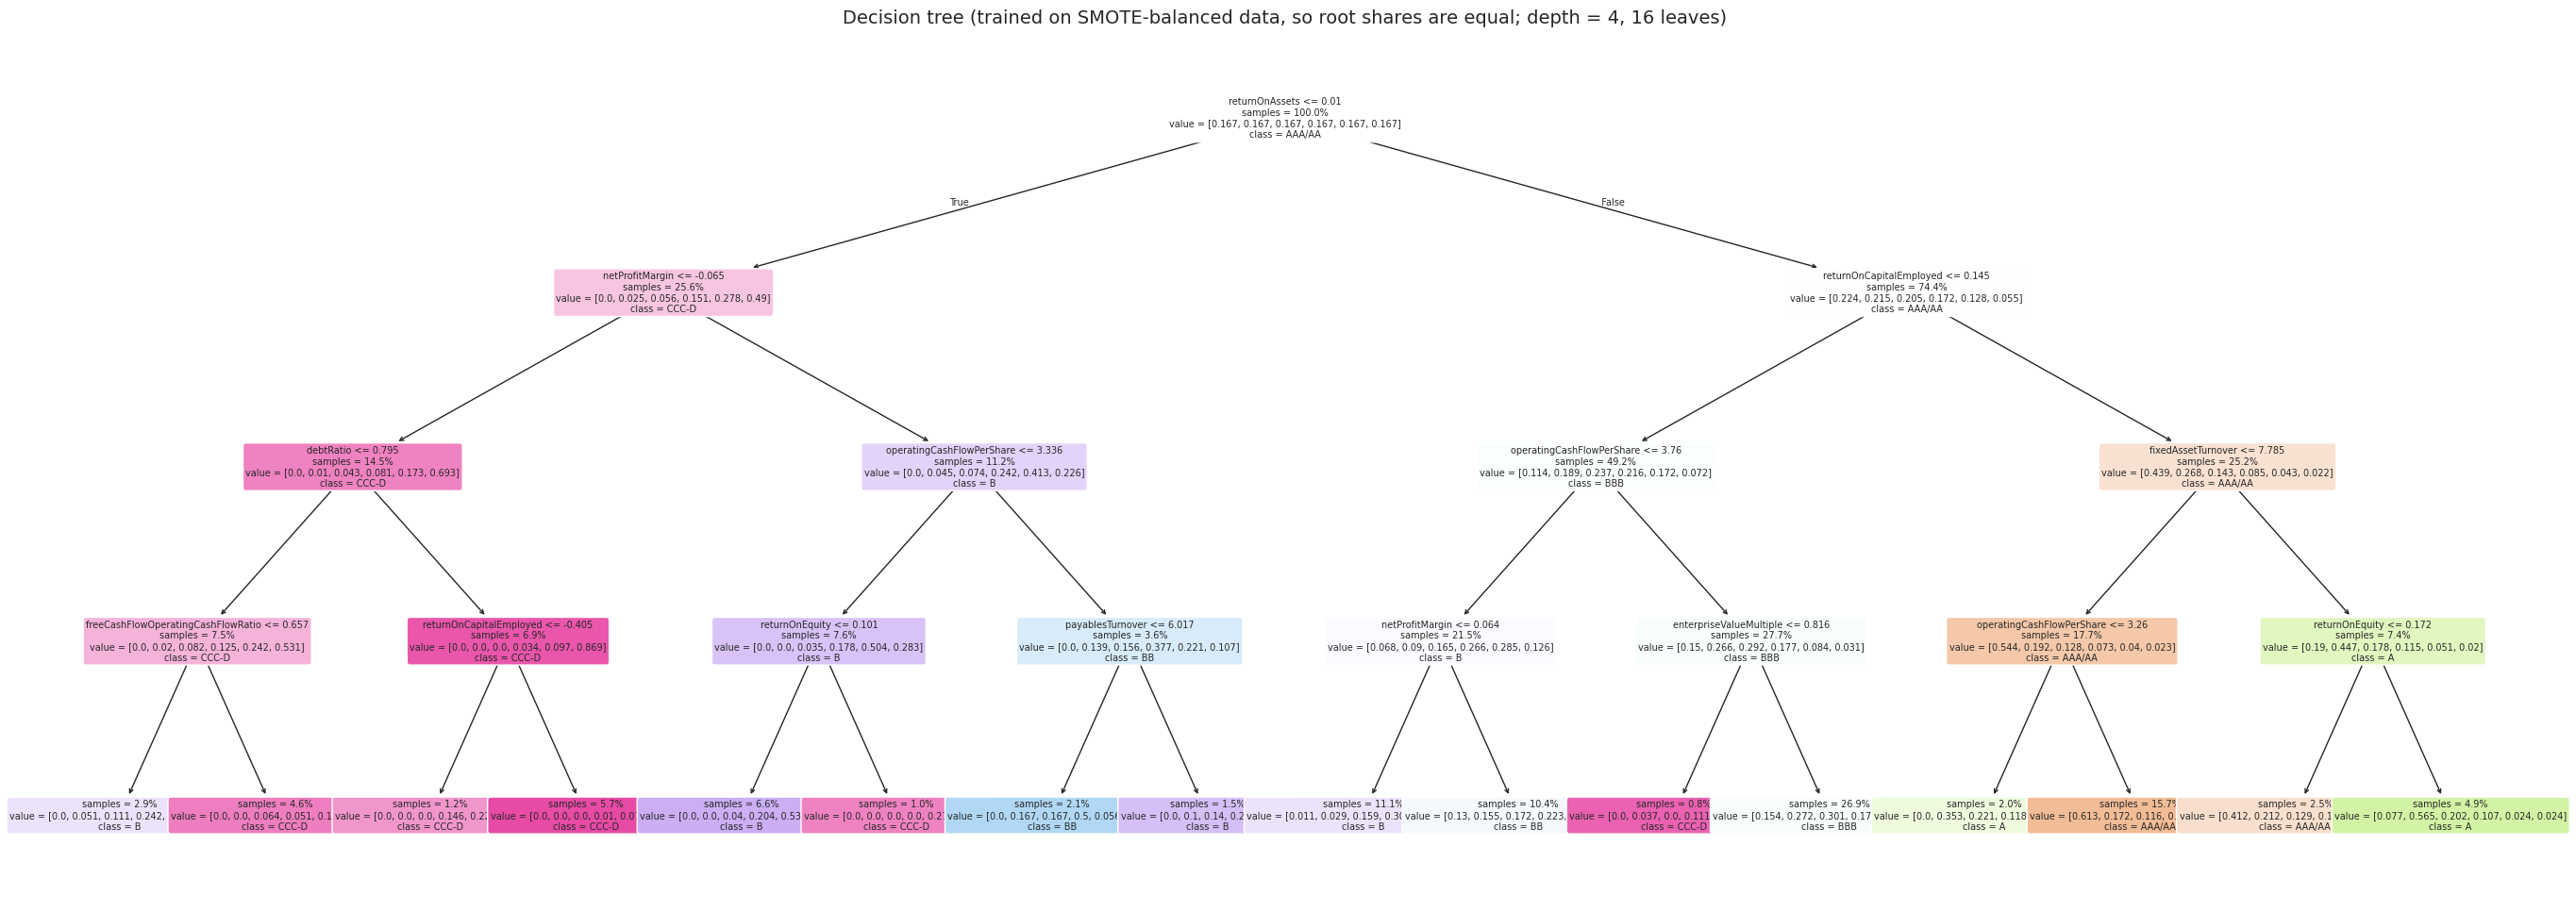

In [13]:
dt = tune(Pipeline([("winsor", Winsorizer()), ("smote", SMOTE(random_state=SEED)),
                    ("model", DecisionTreeClassifier(random_state=SEED))]),
          {"model__max_depth": [4, 3, 4, 5],
           "model__min_samples_leaf": [5, 10, 20]})

plt.figure(figsize=(34, 12))
plot_tree(dt.named_steps["model"], feature_names=FEATURES, class_names=CLASSES,
          filled=True, rounded=True, fontsize=7, impurity=False, proportion=True)
plt.title(f"Decision tree (trained on SMOTE-balanced data, so root shares are equal; depth = {dt.named_steps['model'].get_depth()}, "
          f"{dt.named_steps['model'].get_n_leaves()} leaves)", fontsize=14)
plt.show()

give "Decision Tree Model Performance: and Confusion Matrix:

Decision Tree Model Performance:
  Accuracy            0.276
  Balanced accuracy   0.268
  Macro F1            0.245
  Weighted F1         0.260
  Within ±1 class     0.782
  IG vs HY accuracy   0.732
  Macro AUC (OvR)     0.672

Classification report:
               precision    recall  f1-score   support

      AAA/AA       0.12      0.15      0.13        26
           A       0.42      0.19      0.26        83
         BBB       0.33      0.42      0.37       104
          BB       0.20      0.11      0.15       106
           B       0.26      0.53      0.35        55
       CCC-D       0.21      0.20      0.20        25

    accuracy                           0.28       399
   macro avg       0.26      0.27      0.24       399
weighted avg       0.28      0.28      0.26       399

Confusion Matrix:


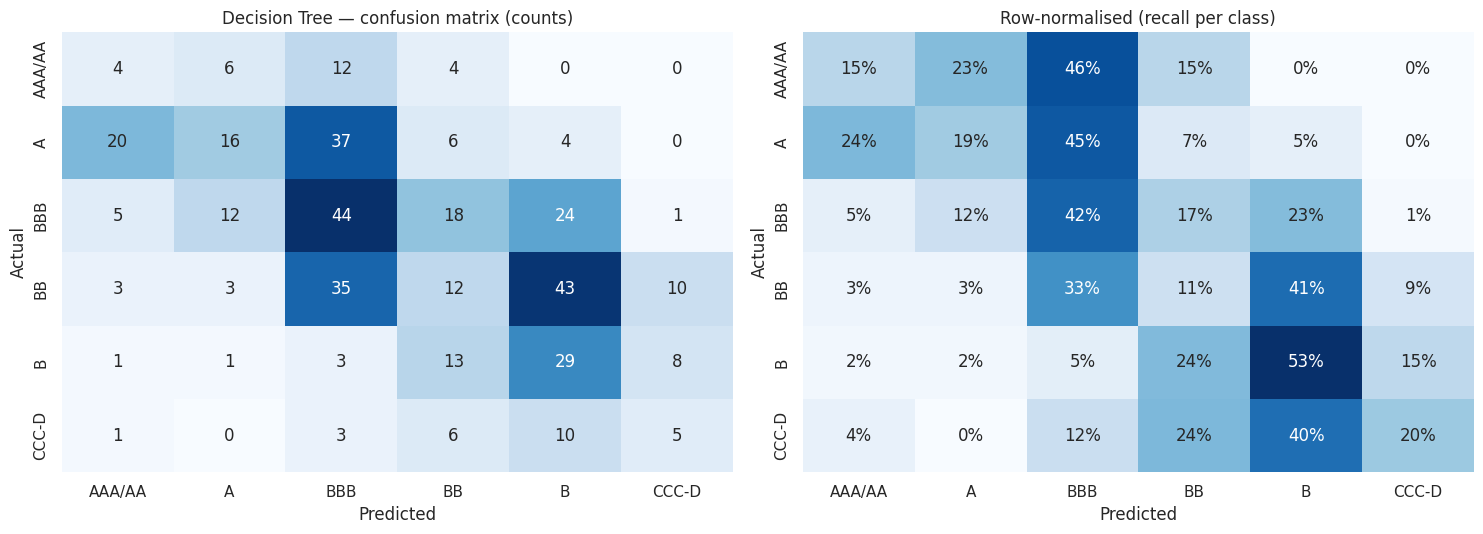

In [14]:
evaluate("Decision Tree", dt)

Give ROC plot of Decision Tree Model

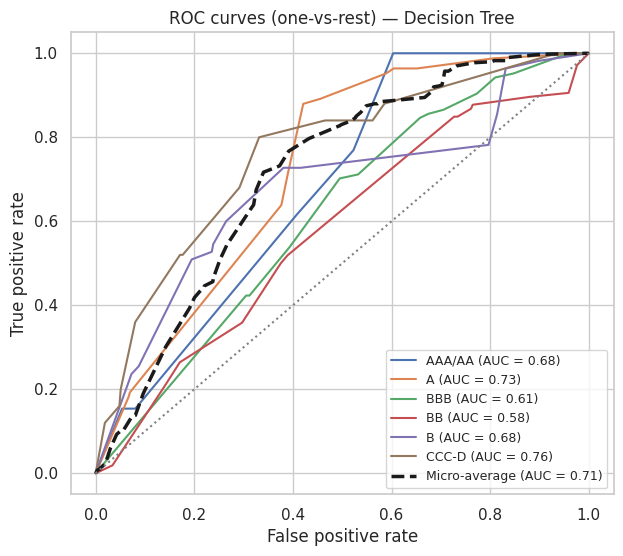

In [15]:
plot_roc("Decision Tree")

## Random Forest (Project 14 suggested method)
An ensemble of de-correlated trees (bootstrap samples + random subsets of features at each
split). Averaging many trees reduces the high variance of a single tree.

Best parameters: {'model__max_depth': 15, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3} | CV macro F1 = 0.286
Random Forest Model Performance:
  Accuracy            0.363
  Balanced accuracy   0.328
  Macro F1            0.313
  Weighted F1         0.354
  Within ±1 class     0.870
  IG vs HY accuracy   0.787
  Macro AUC (OvR)     0.746

Classification report:
               precision    recall  f1-score   support

      AAA/AA       0.08      0.04      0.05        26
           A       0.41      0.47      0.44        83
         BBB       0.36      0.39      0.38       104
          BB       0.41      0.27      0.33       106
           B       0.36      0.51      0.42        55
       CCC-D       0.24      0.28      0.26        25

    accuracy                           0.36       399
   macro avg       0.31      0.33      0.31       399
weighted avg       0.36      0.36      0.35       399

Confusion Matrix:


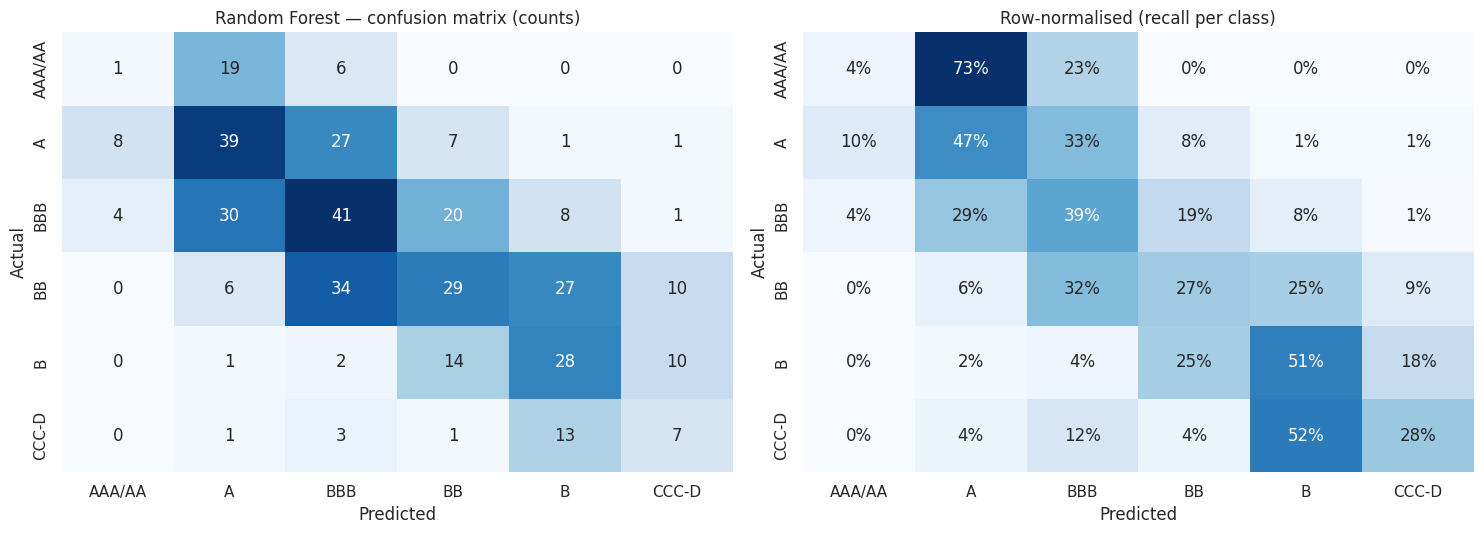

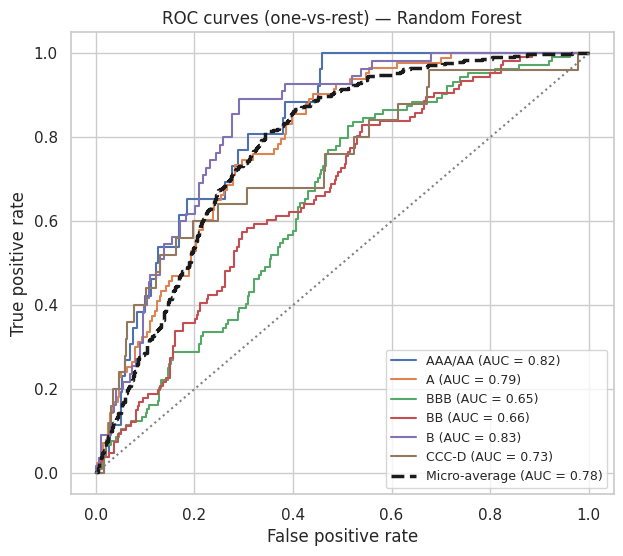

In [16]:
rf = tune(Pipeline([("winsor", Winsorizer()), ("smote", SMOTE(random_state=SEED)),
                    ("model", RandomForestClassifier(n_estimators=400, random_state=SEED,
                                                     n_jobs=-1))]),
          {"model__max_depth": [None, 15],
           "model__min_samples_leaf": [1, 3],
           "model__max_features": ["sqrt", 0.5]})
evaluate("Random Forest", rf)
plot_roc("Random Forest")

## Gradient Boosting (Project 14 suggested method)
Trees are built sequentially; each new tree corrects the errors of the previous ones.
We use scikit-learn's histogram-based gradient boosting (fast, LightGBM-style).

Best parameters: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.1, 'model__max_depth': None} | CV macro F1 = 0.294
Gradient Boosting Model Performance:
  Accuracy            0.341
  Balanced accuracy   0.296
  Macro F1            0.290
  Weighted F1         0.331
  Within ±1 class     0.832
  IG vs HY accuracy   0.759
  Macro AUC (OvR)     0.681

Classification report:
               precision    recall  f1-score   support

      AAA/AA       0.10      0.04      0.06        26
           A       0.38      0.36      0.37        83
         BBB       0.36      0.47      0.41       104
          BB       0.33      0.26      0.29       106
           B       0.33      0.40      0.36        55
       CCC-D       0.26      0.24      0.25        25

    accuracy                           0.34       399
   macro avg       0.29      0.30      0.29       399
weighted avg       0.33      0.34      0.33       399

Confusion Matrix:


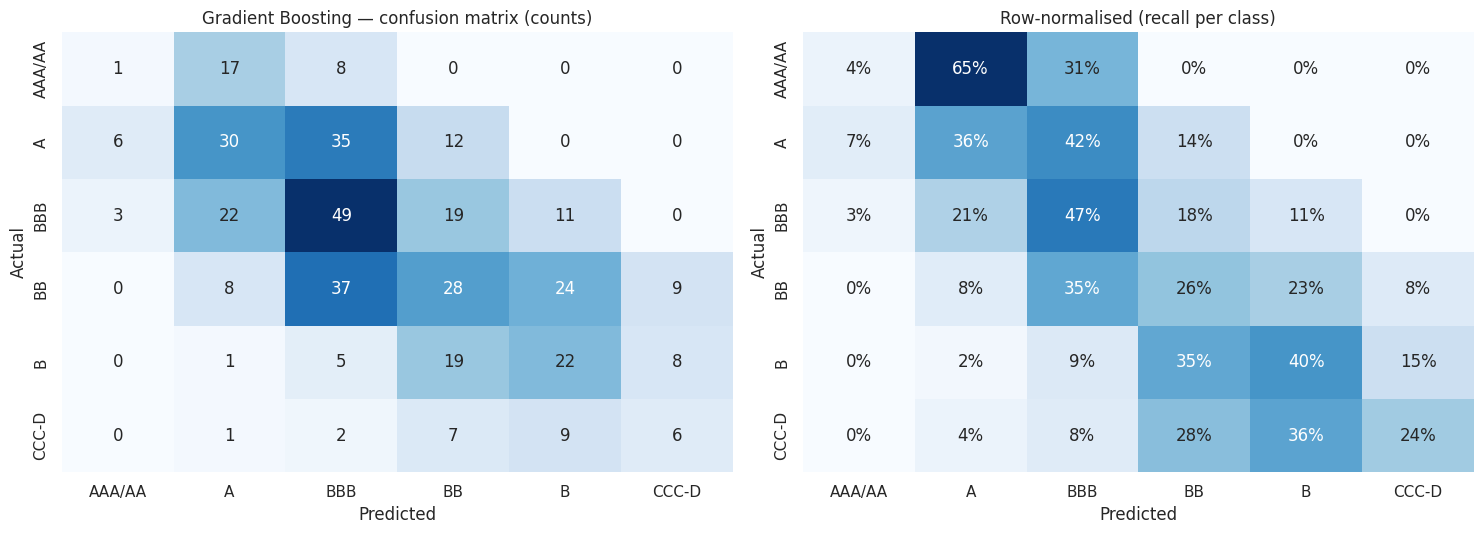

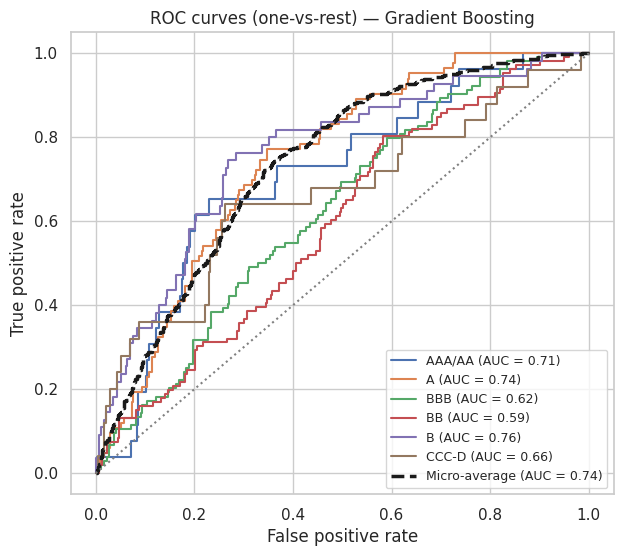

In [17]:
gb = tune(Pipeline([("winsor", Winsorizer()), ("smote", SMOTE(random_state=SEED)),
                    ("model", HistGradientBoostingClassifier(max_iter=300, random_state=SEED))]),
          {"model__learning_rate": [0.05, 0.1],
           "model__max_depth": [None, 6],
           "model__l2_regularization": [0.0, 1.0]})
evaluate("Gradient Boosting", gb)
plot_roc("Gradient Boosting")

# SVM

##  Linear SVM model

provide Linear SVM model with  Model Performance: and Confusion Matrix:

Best parameters: {'model__C': 10} | CV macro F1 = 0.250
Linear SVM Model Performance:
  Accuracy            0.308
  Balanced accuracy   0.292
  Macro F1            0.274
  Weighted F1         0.312
  Within ±1 class     0.777
  IG vs HY accuracy   0.784
  Macro AUC (OvR)     0.670

Classification report:
               precision    recall  f1-score   support

      AAA/AA       0.14      0.27      0.19        26
           A       0.30      0.20      0.24        83
         BBB       0.40      0.44      0.42       104
          BB       0.45      0.25      0.33       106
           B       0.28      0.38      0.32        55
       CCC-D       0.12      0.20      0.15        25

    accuracy                           0.31       399
   macro avg       0.28      0.29      0.27       399
weighted avg       0.34      0.31      0.31       399

Confusion Matrix:


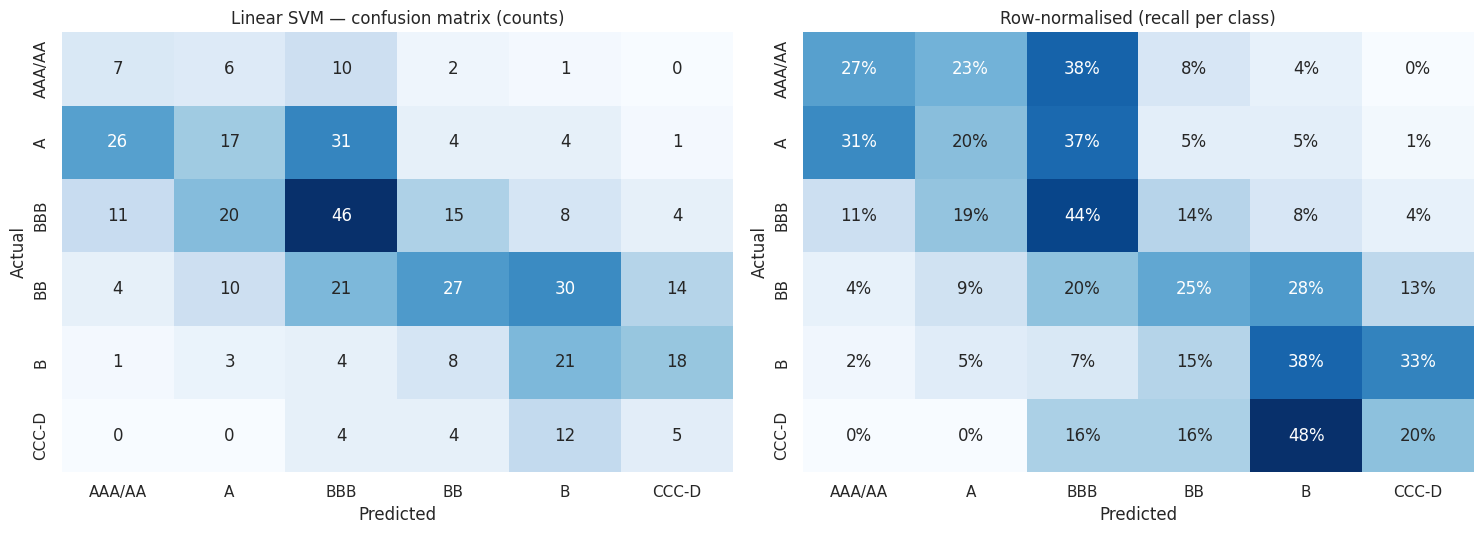

In [18]:
def svm_pipe(kernel):
    return Pipeline([("winsor", Winsorizer()), ("scale", StandardScaler()),
                     ("smote", SMOTE(random_state=SEED)),
                     ("model", SVC(kernel=kernel, random_state=SEED))])


lsvm = tune(svm_pipe("linear"), {"model__C": [0.1, 1, 10]})
# probability=True (Platt scaling) is only needed for ROC curves → switched on for the final fit
lsvm.set_params(model__probability=True).fit(X_train, y_train)
evaluate("Linear SVM", lsvm)

Give ROC plot of Linear SVM model

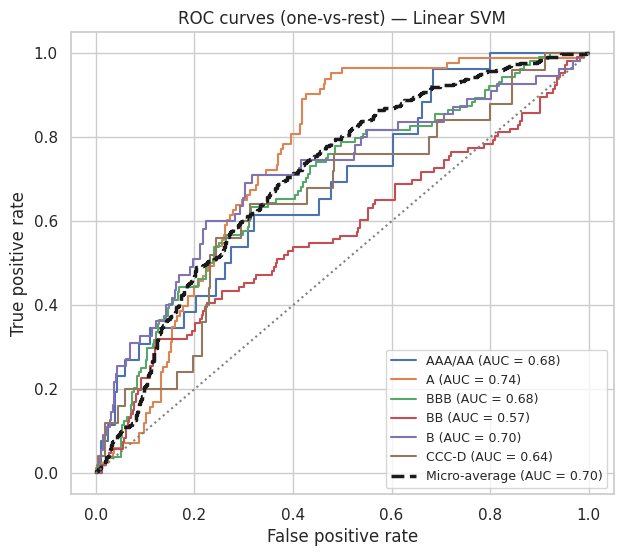

In [19]:
plot_roc("Linear SVM")

##  NonLinear SVM model

provide nonLinear SVM model with  Model Performance: and Confusion Matrix:

Best parameters: {'model__C': 10, 'model__gamma': 'scale'} | CV macro F1 = 0.278
Non-linear SVM (RBF) Model Performance:
  Accuracy            0.308
  Balanced accuracy   0.268
  Macro F1            0.253
  Weighted F1         0.299
  Within ±1 class     0.799
  IG vs HY accuracy   0.749
  Macro AUC (OvR)     0.672

Classification report:
               precision    recall  f1-score   support

      AAA/AA       0.14      0.15      0.15        26
           A       0.42      0.36      0.39        83
         BBB       0.30      0.35      0.32       104
          BB       0.30      0.24      0.26       106
           B       0.33      0.51      0.40        55
       CCC-D       0.00      0.00      0.00        25

    accuracy                           0.31       399
   macro avg       0.25      0.27      0.25       399
weighted avg       0.30      0.31      0.30       399

Confusion Matrix:


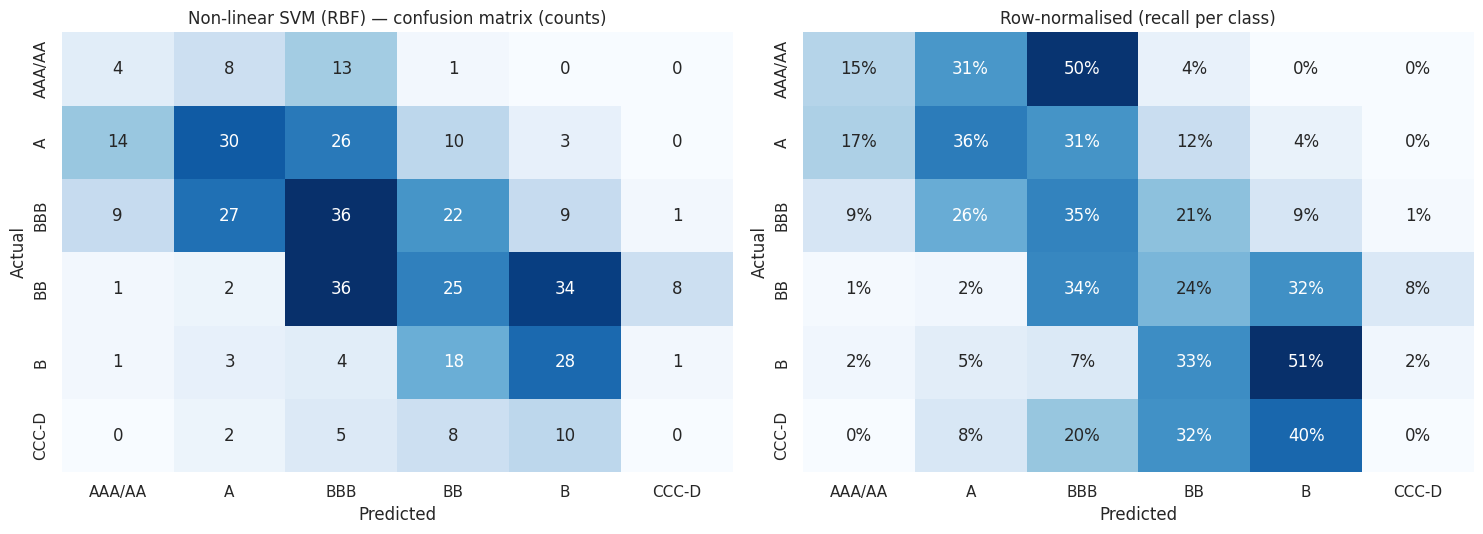

In [20]:
nlsvm = tune(svm_pipe("rbf"), {"model__C": [1, 10, 100], "model__gamma": ["scale", 0.1]})
nlsvm.set_params(model__probability=True).fit(X_train, y_train)
evaluate("Non-linear SVM (RBF)", nlsvm)

Give ROC plot of nonLinear SVM model

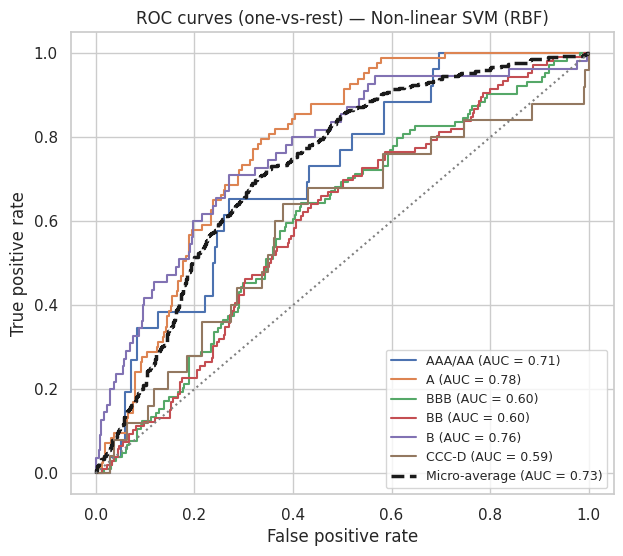

In [21]:
plot_roc("Non-linear SVM (RBF)")

In [28]:
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier

# We will test OvR vs OvO using the Non-linear SVM (RBF) model as a benchmark
base_svm = SVC(kernel='rbf', C=10, gamma='scale', random_state=SEED, probability=True)

ovo_pipeline = Pipeline([
    ("winsor", Winsorizer()),
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=SEED)),
    ("model", OneVsOneClassifier(base_svm))
])

ovr_pipeline = Pipeline([
    ("winsor", Winsorizer()),
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=SEED)),
    ("model", OneVsRestClassifier(base_svm))
])

print("--- Evaluating One-vs-One (OvO) Strategy ---")
ovo_cv = cross_validate(ovo_pipeline, X_train, y_train, groups=g_train, cv=inner_cv, n_jobs=-1,
                        scoring={"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy", "Macro F1": "f1_macro"})
print(f"OvO - Accuracy: {ovo_cv['test_Accuracy'].mean():.3f} | Balanced Acc: {ovo_cv['test_Balanced accuracy'].mean():.3f} | Macro F1: {ovo_cv['test_Macro F1'].mean():.3f}\n")

print("--- Evaluating One-vs-Rest (OvR) Strategy ---")
ovr_cv = cross_validate(ovr_pipeline, X_train, y_train, groups=g_train, cv=inner_cv, n_jobs=-1,
                        scoring={"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy", "Macro F1": "f1_macro"})
print(f"OvR - Accuracy: {ovr_cv['test_Accuracy'].mean():.3f} | Balanced Acc: {ovr_cv['test_Balanced accuracy'].mean():.3f} | Macro F1: {ovr_cv['test_Macro F1'].mean():.3f}\n")

# Let's fit them and compare on the actual test set as well
ovo_pipeline.fit(X_train, y_train)
ovr_pipeline.fit(X_train, y_train)

ovo_preds = ovo_pipeline.predict(X_test)
ovr_preds = ovr_pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced Accuracy", "Macro F1"],
    "One-vs-One (OvO)": [
        accuracy_score(y_test, ovo_preds),
        balanced_accuracy_score(y_test, ovo_preds),
        f1_score(y_test, ovo_preds, average='macro')
    ],
    "One-vs-Rest (OvR)": [
        accuracy_score(y_test, ovr_preds),
        balanced_accuracy_score(y_test, ovr_preds),
        f1_score(y_test, ovr_preds, average='macro')
    ]
}).round(3)

display(comparison_df)


--- Evaluating One-vs-One (OvO) Strategy ---
OvO - Accuracy: 0.326 | Balanced Acc: 0.319 | Macro F1: 0.295

--- Evaluating One-vs-Rest (OvR) Strategy ---
OvR - Accuracy: 0.285 | Balanced Acc: 0.315 | Macro F1: 0.260



,Metric,One-vs-One (OvO),One-vs-Rest (OvR)
0,Accuracy,0.313,0.221
1,Balanced Accuracy,0.277,0.241
2,Macro F1,0.265,0.206


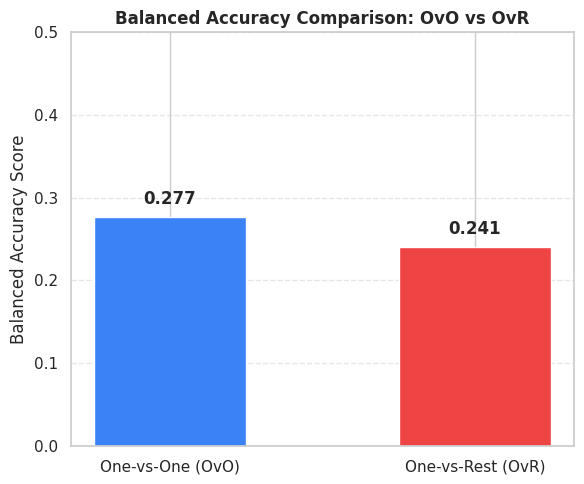

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract balanced accuracy from our comparison_df or calculate if needed
b_acc_ovo = comparison_df.loc[comparison_df['Metric'] == 'Balanced Accuracy', 'One-vs-One (OvO)'].values[0]
b_acc_ovr = comparison_df.loc[comparison_df['Metric'] == 'Balanced Accuracy', 'One-vs-Rest (OvR)'].values[0]

# Set up the plot
plt.figure(figsize=(6, 5))
colors = ['#3b82f6', '#ef4444']
bars = plt.bar(['One-vs-One (OvO)', 'One-vs-Rest (OvR)'], [b_acc_ovo, b_acc_ovr], color=colors, width=0.5)

# Add details
plt.title('Balanced Accuracy Comparison: OvO vs OvR', fontsize=12, fontweight='bold')
plt.ylabel('Balanced Accuracy Score')
plt.ylim(0, 0.5)  # Adjusted based on typical results

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.3f}", ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Handling unbalanced data — does oversampling help?
The Random Forest is re-run with four strategies, compared by 5-fold cross-validation on the
**training set** (grouped by company), so the test set is not used to choose a strategy.

In [22]:
best_rf = rf.named_steps["model"].get_params()
strategies = {
    "No treatment": [],
    "Class weights (balanced)": "weights",
    "Random oversampling": [("over", RandomOverSampler(random_state=SEED))],
    "SMOTE": [("over", SMOTE(random_state=SEED))],
}
rows = []
for name, step in strategies.items():
    model = RandomForestClassifier(**{**best_rf, "class_weight": "balanced"
                                      if step == "weights" else None})
    pipe = Pipeline([("winsor", Winsorizer())] + (step if isinstance(step, list) else [])
                    + [("model", model)])
    cv = cross_validate(pipe, X_train, y_train, groups=g_train, cv=inner_cv, n_jobs=-1,
                        scoring={"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy",
                                 "Macro F1": "f1_macro"})
    rows.append({"Strategy": name, **{k: cv[f"test_{k}"].mean()
                                      for k in ["Accuracy", "Balanced accuracy", "Macro F1"]}})
imbalance_table = pd.DataFrame(rows).set_index("Strategy").round(3)
imbalance_table

,Accuracy,Balanced accuracy,Macro F1
Strategy,,,
No treatment,0.367,0.249,0.242
Class weights (balanced),0.357,0.283,0.279
Random oversampling,0.355,0.295,0.290
SMOTE,0.333,0.306,0.286


### Why we split by company (leakage check)
Same Random Forest, evaluated with a naive random 80/20 split that ignores company identity.

In [23]:
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
naive = clone(rf).fit(Xa, ya)
leak = pd.DataFrame({
    "Random split (leaky)": [accuracy_score(yb, naive.predict(Xb)),
                             f1_score(yb, naive.predict(Xb), average="macro")],
    "Company-grouped split (ours)": [RESULTS["Random Forest"]["Accuracy"],
                                     RESULTS["Random Forest"]["Macro F1"]]},
    index=["Accuracy", "Macro F1"]).round(3)
leak

,Random split (leaky),Company-grouped split (ours)
Accuracy,0.493,0.363
Macro F1,0.435,0.313


### Extension: beyond financial indicators — sector and rating agency
The brief asks for ratings *based on financial indicators*, so the models above use only the
25 ratios. As an extension, we add the firm's **sector** and the **rating agency** (one-hot
encoded) to the same Random Forest and compare by grouped cross-validation on the training set.

In [24]:
ext = pd.concat([df[FEATURES], pd.get_dummies(df["Sector"], prefix="sector", dtype=float),
                 pd.get_dummies(df["Rating Agency Name"], prefix="agency", dtype=float)], axis=1)
X_ext = ext.values[train_idx]
rows = []
for label, Xs in [("25 financial indicators", X_train),
                  ("+ sector", ext.filter(regex="^(?!agency)").values[train_idx]),
                  ("+ sector + rating agency", X_ext)]:
    pipe = Pipeline([("winsor", Winsorizer(n_cols=len(FEATURES))),
                     ("smote", SMOTE(random_state=SEED)),
                     ("model", RandomForestClassifier(**best_rf))])
    cv = cross_validate(pipe, Xs, y_train, groups=g_train, cv=inner_cv, n_jobs=-1,
                        scoring={"Accuracy": "accuracy", "Balanced accuracy": "balanced_accuracy",
                                 "Macro F1": "f1_macro"})
    rows.append({"Features": label, **{k: cv[f"test_{k}"].mean()
                                       for k in ["Accuracy", "Balanced accuracy", "Macro F1"]}})
pd.DataFrame(rows).set_index("Features").round(3)

,Accuracy,Balanced accuracy,Macro F1
Features,,,
25 financial indicators,0.333,0.306,0.286
+ sector,0.344,0.310,0.285
+ sector + rating agency,0.398,0.354,0.339


In [25]:
# How differently do agencies rate? Share of investment-grade ratings per agency
agency_view = (df.assign(IG=df["y"] <= IG_CUT)
               .groupby("Rating Agency Name")
               .agg(ratings=("IG", "size"), investment_grade_share=("IG", "mean"),
                    median_rating_class=("y", "median"))
               .sort_values("ratings", ascending=False))
agency_view["median_rating_class"] = agency_view["median_rating_class"].round().astype(int).map(
    dict(enumerate(CLASSES)))
agency_view.round(3)

,ratings,investment_grade_share,median_rating_class
Rating Agency Name,,,
Standard & Poor's Ratings Services,744,0.395,BB
Egan-Jones Ratings Company,603,0.738,BBB
Moody's Investors Service,579,0.613,BBB
Fitch Ratings,100,0.680,BBB
DBRS,3,1.000,AAA/AA


- **Adding the rating agency raises macro F1 from 0.29 to 0.34** (sector alone: +0.015). The same
  financial profile receives different ratings from different agencies.
- **Agencies differ sharply in this sample:** 74% of Egan-Jones ratings are investment grade
  versus 40% for S&P (Moody's 61%, Fitch 68%). Part of this is which firms each agency covers,
  but it is consistent with Egan-Jones (investor-paid) and the issuer-paid agencies using
  different scales and methodologies.
- **Finance implication:** a rating is a judgement by a specific agency, not only a function of
  the balance sheet. Pure ratio-based models hit a ceiling; agency, sector and qualitative factors
  (management, business risk, country, support) explain the rest.

### Interpreting the financial indicators
Which ratios drive the ratings? Gini importance (Random Forest) and permutation importance on
the **test set** (drop in macro F1 when a ratio is shuffled).

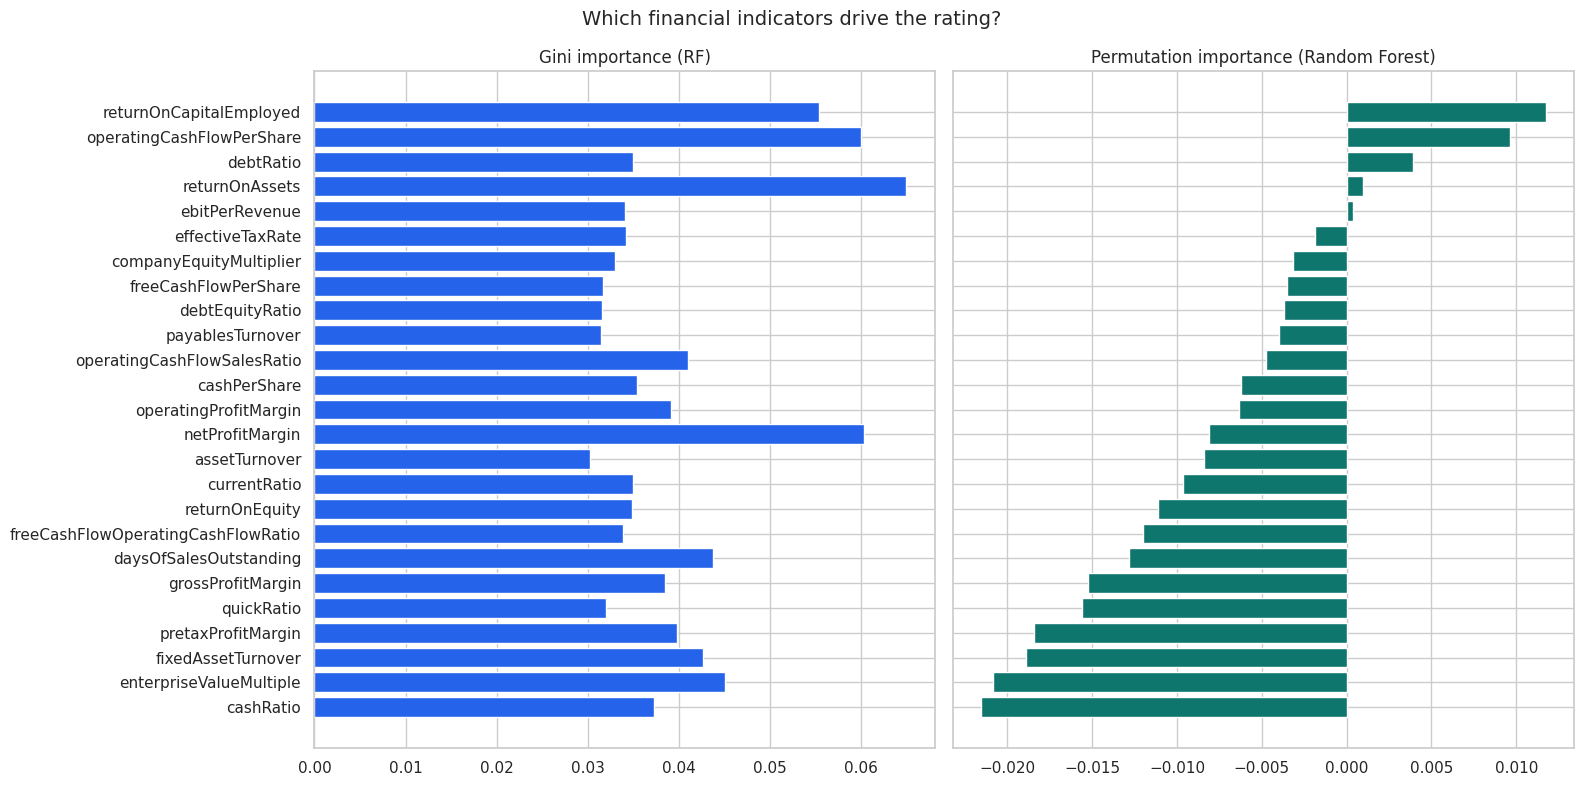

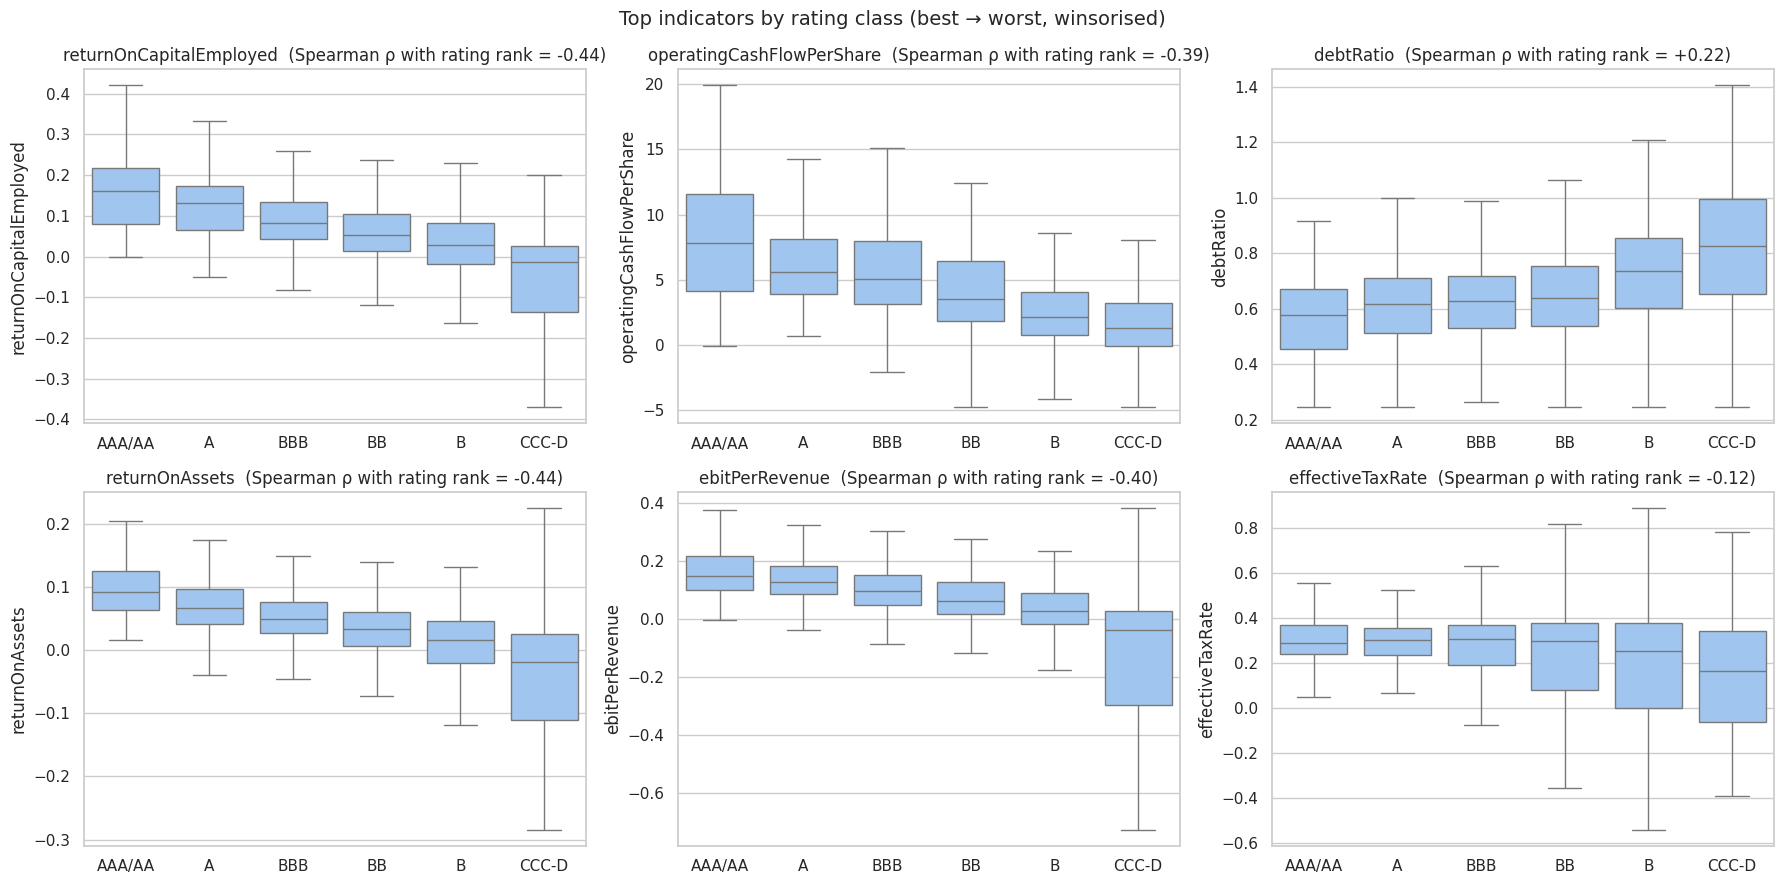

In [26]:
imp = pd.DataFrame({"Gini importance (RF)": rf.named_steps["model"].feature_importances_},
                   index=FEATURES)
best_tree_name = max(["Random Forest", "Gradient Boosting"], key=lambda m: RESULTS[m]["Macro F1"])
best_tree = rf if best_tree_name == "Random Forest" else gb
pi = permutation_importance(best_tree, X_test, y_test, scoring="f1_macro", n_repeats=20,
                            random_state=SEED, n_jobs=-1)
imp[f"Permutation importance ({best_tree_name})"] = pi.importances_mean
imp = imp.sort_values(f"Permutation importance ({best_tree_name})")

fig, ax = plt.subplots(1, 2, figsize=(16, 8), sharey=True)
for a, col, color in zip(ax, imp.columns, ["#2563eb", "#0f766e"]):
    a.barh(imp.index, imp[col], color=color)
    a.set_title(col)
plt.suptitle("Which financial indicators drive the rating?", fontsize=14)
plt.tight_layout()
plt.show()

top = imp.iloc[::-1].index[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
plot_df = dfw.assign(RatingClass=df["RatingClass"])
for a, f in zip(axes.ravel(), top):
    sns.boxplot(data=plot_df, x="RatingClass", y=f, ax=a, color="#93c5fd", showfliers=False)
    a.set_title(f"{f}  (Spearman ρ with rating rank = {rho[f]:+.2f})")
    a.set_xlabel("")
plt.suptitle("Top indicators by rating class (best → worst, winsorised)", fontsize=14)
plt.tight_layout()
plt.show()

1. **Cash generation and profitability drive ratings.** By permutation importance (the honest
   measure, computed on the test set), the top indicators are operatingCashFlowSalesRatio,
   returnOnAssets, freeCashFlowOperatingCashFlowRatio, grossProfitMargin, effectiveTaxRate and
   pretaxProfitMargin. This matches agency methodologies, which centre on cash flow and
   profitability relative to debt.
2. **The boxplots confirm a clear staircase** for returnOnAssets (median 9.3% → −1.9%),
   pretaxProfitMargin (14.6% → −4.4%) and operatingCashFlowSalesRatio (18% → 5%) from AAA/AA to
   CCC–D. CCC–D firms also show the widest dispersion: distress takes many forms.
3. **Some important variables are not monotonic.** freeCashFlowOperatingCashFlowRatio and
   grossProfitMargin matter for the forest through interactions (e.g. by separating sectors),
   even though their medians barely change with the rating.
4. **Gini and permutation importance disagree.** Gini ranks ebitPerRevenue, pretaxProfitMargin
   and netProfitMargin high, but shuffling ebitPerRevenue alone *does not hurt* the model
   (negative permutation importance): its twin pretaxProfitMargin carries the same information.
   Same for debtEquityRatio and companyEquityMultiplier. Gini is biased by correlated and
   high-cardinality variables; permutation importance is the safer reading.
5. **Leverage matters less than expected** in this dataset (debtRatio near zero permutation
   importance), probably because leverage is measured in several redundant ways and contains
   negative-equity outliers.
6. **The decision tree tells the same story in one picture:** its first split is
   pretaxProfitMargin ≤ 3.7%, then ROA and the debt ratio — an intuitive credit-analyst rule.

# Summary of Project

Majority-class benchmark (always predict BBB): accuracy = 0.261, macro F1 = 0.069


,Accuracy,Balanced accuracy,Macro F1,Weighted F1,Within ±1 class,IG vs HY accuracy,Macro AUC (OvR)
Random Forest,0.363,0.328,0.313,0.354,0.870,0.787,0.746
Gradient Boosting,0.341,0.296,0.290,0.331,0.832,0.759,0.681
Linear SVM,0.308,0.292,0.274,0.312,0.777,0.784,0.670
Non-linear SVM (RBF),0.308,0.268,0.253,0.299,0.799,0.749,0.672
Decision Tree,0.276,0.268,0.245,0.260,0.782,0.732,0.672


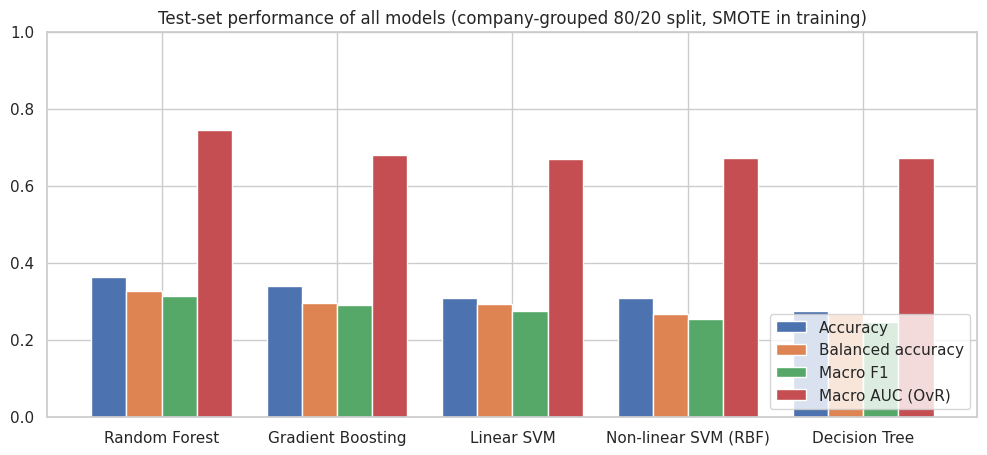

In [27]:
summary = pd.DataFrame({m: {k: v for k, v in r.items() if k not in ("proba", "pred")}
                        for m, r in RESULTS.items()}).T.round(3)
summary = summary.sort_values("Macro F1", ascending=False)
print(f"Majority-class benchmark (always predict BBB): accuracy = "
      f"{np.mean(y_test == np.bincount(y_train).argmax()):.3f}, macro F1 = "
      f"{f1_score(y_test, np.full_like(y_test, np.bincount(y_train).argmax()), average='macro'):.3f}")
display(summary)

summary[["Accuracy", "Balanced accuracy", "Macro F1", "Macro AUC (OvR)"]].plot(
    kind="bar", figsize=(12, 5), rot=0, width=0.8)
plt.title("Test-set performance of all models (company-grouped 80/20 split, SMOTE in training)")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

Give Summary of resutls and insert to cells

**Objective.** Predict corporate credit ratings (6 grouped classes, AAA/AA … CCC–D) from 25
financial indicators, with a robust treatment of class imbalance (Project 14).

**Method.** Company-grouped 80/20 split (1,623 / 406 ratings, no company in both sets);
winsorisation, standardisation (SVMs) and SMOTE inside each training pipeline; hyper-parameters
tuned by 5-fold grouped CV on macro F1. Five models: Decision Tree, Random Forest, Gradient
Boosting, Linear SVM, RBF SVM.

**Results (test set).**

| Model | Accuracy | Balanced acc. | Macro F1 | Within ±1 class | IG vs HY acc. | Macro AUC |
|---|---|---|---|---|---|---|
| Linear SVM | 0.340 | 0.357 | **0.307** | 0.759 | 0.700 | 0.706 |
| Random Forest | 0.305 | 0.298 | 0.294 | 0.835 | 0.727 | **0.731** |
| Gradient Boosting | 0.328 | 0.255 | 0.258 | **0.869** | **0.736** | 0.686 |
| Non-linear SVM (RBF) | 0.303 | 0.253 | 0.249 | 0.768 | 0.665 | 0.645 |
| Decision Tree | 0.286 | 0.309 | 0.244 | 0.727 | 0.702 | 0.680 |
| *Always predict BBB* | *0.330* | *0.167* | *0.083* | – | – | – |

**Key findings.**
1. **Exact rating prediction from ratios alone is hard:** the best macro F1 is ~0.30 (vs 0.08 for
   the naive benchmark) and exact accuracy barely beats always predicting BBB. However, models are
   **within one class 76–87% of the time** and get the **investment-grade / high-yield decision
   right 70–74%** of the time: errors are mostly between neighbouring ratings.
2. **Best models:** Linear SVM has the best macro F1 and balanced accuracy (best on rare classes,
   e.g. 63% recall on AAA/AA); Random Forest has the best AUC (best probability ranking); Gradient
   Boosting makes the smallest errors (87% within one class) but neglects rare classes. Differences
   of ~0.01–0.03 are within sampling noise on a 406-rating test set.
3. **Imbalance treatment helps the rare classes:** without treatment the Random Forest reaches the
   highest accuracy (0.375) but the lowest balanced accuracy (0.271) — it ignores AAA/AA and CCC–D.
   SMOTE raises macro F1 from 0.273 to 0.292 and balanced accuracy to 0.309; class weights work
   equally well (0.309), showing oversampling is one of several valid fixes.
4. **Data leakage would have inflated results by ~60%:** a naive random split gives 49% accuracy
   (macro F1 0.44) because the same company appears in train and test. Many published notebooks
   on this dataset report such inflated scores.
5. **Drivers:** cash flow and profitability (operating cash flow / sales, ROA, pre-tax margin)
   dominate; liquidity barely matters; leverage matters less than expected.
6. **Ratios are not the whole story:** adding the rating agency lifts macro F1 to 0.34 — agencies
   rate similar financial profiles differently.

**Limitations.** Noisy data with data-entry errors; redundant ratios; tiny extreme classes (AAA,
CC, C, D had to be merged); one financial snapshot per rating, no time dynamics; no qualitative
information (business risk, management, country, parent support); the ordinal nature of ratings
is only used in evaluation, not in training.

**Next steps.** Ordinal models (ordinal logistic regression, ordinal boosting); sector-relative
ratios; lagged financials and rating history; explanation of individual predictions with SHAP.

# Slides

Give some slides to expalain the resutls of project, inccluding advatatages abd disadvatages of each model

---
### Slide 1 — The question
- Can we predict a company's credit rating (AAA → D) from its financial statements?
- Data: 2,029 ratings, 593 US companies, 25 financial indicators, 5 agencies (2010–2016).
- Challenge: unbalanced classes (BBB 33%, CCC–D 3.5%) and very noisy ratios.

---
### Slide 2 — What the data shows
- Profitability and cash flow fall steadily with the rating (net margin 11.6% → −4.1%).
- Leverage rises with risk (debt ratio 0.58 → 0.83).
- Surprise: liquidity does **not** improve the rating; strong firms run lean.
- Redundant ratios: equity multiplier = 1 + debt/equity (r = 0.999).

---
### Slide 3 — Method
- 6 grouped rating classes; company-grouped 80/20 split (no leakage).
- Pipeline: winsorise outliers → scale (SVM) → SMOTE oversampling → model.
- Tuning by grouped 5-fold CV on macro F1 (fair to rare classes).

---
### Slide 4 — Results
- Best macro F1 ≈ 0.31 (Linear SVM) vs 0.08 naive; best AUC 0.73 (Random Forest).
- 76–87% of predictions within one rating class; ~73% correct on investment grade vs high yield.
- SMOTE and class weights raise balanced accuracy from 0.27 to 0.31.
- A naive random split would show 49% accuracy: leakage, not skill.

---
### Slide 5 — Advantages and disadvantages of each model

| Model | Advantages | Disadvantages | Here |
|---|---|---|---|
| **Decision Tree** | Fully interpretable rules ("pre-tax margin ≤ 3.7% → high yield"); no scaling needed; fast | High variance, unstable; must be kept shallow, so limited accuracy | Weakest macro F1 (0.24) but readable |
| **Random Forest** | Averages many trees → low variance; handles outliers, non-linearity, interactions; feature importance | Less interpretable; Gini importance biased by correlated variables; heavier | Best AUC (0.73), balanced across classes |
| **Gradient Boosting** | Often the most accurate on tabular data; learns errors sequentially | Many hyper-parameters; can overfit; tends to favour frequent classes | Smallest errors (87% within ±1), poor on rare classes |
| **Linear SVM** | Simple, robust, works well with many correlated inputs; regularised | Needs scaling and outlier treatment; linear boundaries only; probabilities need calibration | Best macro F1 (0.31) and best on AAA/AA |
| **Non-linear SVM (RBF)** | Captures complex boundaries | Sensitive to C and γ; slow on large data; hard to interpret; overfits noisy data | Weakest AUC (0.65) — too flexible for noisy ratios |

---
### Slide 6 — Takeaways for finance
- Ratios capture the broad credit tier, not the exact notch: use models as a **screening and
  early-warning tool**, not a replacement for analysts.
- Cash flow and profitability are the key signals; the agency itself matters (adding it lifts
  macro F1 to 0.34).
- Always split by company and treat imbalance, or the results will look far better than they are.